phase 1 code

In [ ]:
!pip install nibabel -q

import os, glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

print("Setup complete")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = "/content/drive/MyDrive/Ms_project"      # matches your real folder name
RAW = f"{PROJECT}/data_raw"

assert os.path.exists(RAW), f"Folder not found: {RAW}"   # stops with a clear error if the path is wrong
os.makedirs(f"{PROJECT}/data_processed", exist_ok=True)
os.makedirs(f"{PROJECT}/outputs", exist_ok=True)

print("Using data folder:", RAW)
print("Contents:", os.listdir(RAW)[:10])

In [ ]:
from collections import Counter

hits = []
for root, dirs, fs in os.walk("/content/drive/MyDrive"):
    for f in fs:
        if f.lower().endswith((".nii", ".nii.gz")):
            hits.append(root)

counts = Counter(hits)
print("Total scan files:", sum(counts.values()), "\n")
for folder, n in counts.most_common(10):
    print(n, "scans in", folder)

In [ ]:
RAW = os.path.commonpath(list(counts))
print("RAW is now:", RAW)

In [ ]:
files = sorted(
    f for f in glob.glob(f"{RAW}/**/*", recursive=True)
    if f.lower().endswith((".nii", ".nii.gz"))
)
print(f"Found {len(files)} NIfTI files\n")
for f in files[:15]:
    print(os.path.relpath(f, RAW))

# If nothing was found, show what IS in the folder
if len(files) == 0:
    from collections import Counter
    ext = Counter()
    for root, dirs, fs in os.walk(RAW):
        for f in fs:
            n = f.lower()
            e = ".nii.gz" if n.endswith(".nii.gz") else os.path.splitext(n)[1]
            ext[e or "(no extension)"] += 1
    print("\nNo .nii/.nii.gz files. File types present:", dict(ext))
    print("If you see .zip, unzip it first. If you see .dcm or .mgz, tell me.")

In [ ]:
import re, pandas as pd

pat = re.compile(r"P(\d+)_T(\d+)_(FLAIR|T1|T2|MASK)", re.IGNORECASE)
rows = []
for f in files:
    m = pat.search(os.path.basename(f))
    if m:
        rows.append(dict(patient=int(m[1]), timepoint=int(m[2]), kind=m[3].upper(), path=f))
df = pd.DataFrame(rows)

print(f"Matched {len(df)} of {len(files)} files")
tp = df[df.kind == "FLAIR"].groupby("patient").timepoint.nunique()
print("\nPatients by number of time points:")
print(tp.value_counts().sort_index())

In [ ]:
shapes = []
for _, r in df.iterrows():
    im = nib.load(r.path)
    shapes.append((im.shape,
                   tuple(round(float(z), 2) for z in im.header.get_zooms()),
                   "".join(nib.aff2axcodes(im.affine))))
print(pd.Series(shapes).value_counts())

have = df.pivot_table(index=["patient", "timepoint"], columns="kind", values="path", aggfunc="count")
print("\nMissing files per type:\n", have.isna().sum())

KeyboardInterrupt: 

In [ ]:
from matplotlib.colors import ListedColormap
red, green = ListedColormap(["red"]), ListedColormap(["lime"])

def path_of(p, t, kind):
    return df[(df.patient == p) & (df.timepoint == t) & (df.kind == kind)].path.iloc[0]

def load(p, t):
    f = nib.load(path_of(p, t, "FLAIR")).get_fdata(dtype=np.float32)
    m = nib.load(path_of(p, t, "MASK")).get_fdata(dtype=np.float32) > 0
    return f, m

def best_slice(vol, shape):
    s = vol.sum(axis=(0, 1))
    return int(s.argmax()) if s.max() > 0 else shape[2] // 2

def overlay(ax, f, m, cmap, alpha=0.6):
    ax.imshow(np.ma.masked_where(~m.T, m.T.astype(float)), cmap=cmap, alpha=alpha, origin="lower")

def show_patient(p):
    tps = sorted(df[(df.patient == p) & (df.kind == "FLAIR")].timepoint.unique())
    f1, m1 = load(p, tps[0])

    if len(tps) >= 2:
        f2, m2 = load(p, tps[1])
        new = m2 & ~m1
        k = best_slice(new if new.any() else m2, f2.shape)
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        ax[0].imshow(f1[:, :, k].T, cmap="gray", origin="lower")
        overlay(ax[0], f1[:, :, k], m1[:, :, k], red)
        ax[0].set_title(f"P{p} time {tps[0]}: lesions (red) | zero frac {(f1 == 0).mean():.2f}")
        ax[1].imshow(f2[:, :, k].T, cmap="gray", origin="lower")
        overlay(ax[1], f2[:, :, k], m1[:, :, k], red)
        overlay(ax[1], f2[:, :, k], new[:, :, k], green, 0.85)
        ax[1].set_title(f"time {tps[1]}: old (red) + NEW (green)")
        ax[2].imshow(f2[:, :, k].T, cmap="gray", origin="lower")
        ax[2].set_title(f"time {tps[1]}: FLAIR only | zero frac {(f2 == 0).mean():.2f}")
        info = f"lesion voxels {int(m1.sum())} -> {int(m2.sum())} | new {int(new.sum())}"
    else:
        k = best_slice(m1, f1.shape)
        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        ax[0].imshow(f1[:, :, k].T, cmap="gray", origin="lower")
        ax[0].set_title(f"P{p} time {tps[0]}: FLAIR | zero frac {(f1 == 0).mean():.2f}")
        ax[1].imshow(f1[:, :, k].T, cmap="gray", origin="lower")
        overlay(ax[1], f1[:, :, k], m1[:, :, k], red)
        ax[1].set_title("with lesion mask (red)")
        info = f"lesion voxels {int(m1.sum())} (single time point)"

    for a in ax:
        a.axis("off")
    plt.show()
    print(f"P{p}: time points {tps} | {info}")

# ---- choose who to show ----
all_patients = sorted(df.patient.unique())          # all 53
followup = tp[tp >= 2].index.tolist()               # the 25 with follow-up

group = followup                                    # or: group = all_patients
start, stop = 0, 5                                  # move through in batches of 5
for p in group[start:stop]:
    show_patient(p)

In [ ]:
def path_of(p, t, kind):
    return df[(df.patient == p) & (df.timepoint == t) & (df.kind == kind)].path.iloc[0]

rows = []
for _, r in df[df.kind == "FLAIR"].iterrows():
    f = np.asarray(nib.load(r.path).dataobj)
    nz = f[f > 0]
    p99 = float(np.percentile(nz, 99)) if nz.size else 0.0
    rows.append(dict(patient=r.patient, timepoint=r.timepoint,
                     zero_frac=round(float((f == 0).mean()), 4),
                     min=round(float(f.min()), 3), max=round(float(f.max()), 1),
                     corner=round(float(f[0, 0, 0]), 4),
                     frac_above_1pct=round(float((f > 0.01 * p99).mean()), 3)))
z = pd.DataFrame(rows).sort_values("zero_frac")

print(z.zero_frac.describe().round(4), "\n")
print("Scans with zero_frac < 0.5:", int((z.zero_frac < 0.5).sum()), "of", len(z))
print("Scans with frac_above_1pct > 0.4:", int((z.frac_above_1pct > 0.4).sum()), "of", len(z), "\n")
print("Lowest zero_frac:\n", z.head(8).to_string(index=False), "\n")
print("Highest zero_frac:\n", z.tail(3).to_string(index=False))

# pictures: 3 lowest zero_frac scans and 1 highest (a normal one for comparison)
pick = list(z.head(3)[["patient", "timepoint"]].itertuples(index=False)) + \
       list(z.tail(1)[["patient", "timepoint"]].itertuples(index=False))
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, (p, t) in zip(ax, pick):
    f = np.asarray(nib.load(path_of(p, t, "FLAIR")).dataobj)
    a.imshow(f[:, :, f.shape[2] // 2].T, cmap="gray", origin="lower")
    a.set_title(f"P{p} T{t} | zero frac {(f == 0).mean():.3f}")
    a.axis("off")
plt.show()


In [ ]:
def path_of(p, t, kind):
    return df[(df.patient == p) & (df.timepoint == t) & (df.kind == kind)].path.iloc[0]

check = [(44, 1), (45, 1), (53, 1), (53, 2)]
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for j, (p, t) in enumerate(check):
    f = np.asarray(nib.load(path_of(p, t, "FLAIR")).dataobj)
    nz = np.argwhere(f > 0)
    lo, hi = nz.min(0), nz.max(0)
    ax[0, j].imshow(f[f.shape[0] // 2, :, :].T, cmap="gray", origin="lower")
    ax[0, j].set_title(f"P{p} T{t}: side view")
    kz = int(lo[2] + 0.15 * (hi[2] - lo[2]))
    ax[1, j].imshow(f[:, :, kz].T, cmap="gray", origin="lower")
    ax[1, j].set_title("axial slice near the bottom")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
def path_of(p, t, kind):
    return df[(df.patient == p) & (df.timepoint == t) & (df.kind == kind)].path.iloc[0]

# ---- Part 1: shape of the nonzero region ----
check = [(44, 1), (45, 1), (53, 1), (53, 2)]
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for j, (p, t) in enumerate(check):
    f = np.asarray(nib.load(path_of(p, t, "FLAIR")).dataobj)
    mk = np.asarray(nib.load(path_of(p, t, "MASK")).dataobj) > 0
    b = f > 0
    ax[0, j].imshow(b[b.shape[0] // 2, :, :].T, cmap="gray", origin="lower")
    ax[0, j].set_title(f"P{p} T{t}: nonzero region, side view")
    ax[1, j].imshow(b[:, :, b.shape[2] // 2].T, cmap="gray", origin="lower")
    ax[1, j].set_title("nonzero region, middle axial")
    ax[0, j].axis("off"); ax[1, j].axis("off")
    print(f"P{p} T{t}: lesion voxels outside nonzero region = {int((mk & ~b).sum())}")
plt.tight_layout(); plt.show()

# ---- Part 2: are time points of each follow-up patient aligned? ----
followup = tp[tp >= 2].index.tolist()
rows = []
for p in followup:
    tps = sorted(df[(df.patient == p) & (df.kind == "FLAIR")].timepoint.unique())
    for ta, tb in zip(tps[:-1], tps[1:]):
        a = np.asarray(nib.load(path_of(p, ta, "FLAIR")).dataobj) > 0
        b = np.asarray(nib.load(path_of(p, tb, "FLAIR")).dataobj) > 0
        dice = 2 * (a & b).sum() / (a.sum() + b.sum())
        rows.append(dict(patient=p, t_from=ta, t_to=tb,
                         brain_overlap=round(float(dice), 3),
                         volume_ratio=round(float(b.sum() / a.sum()), 2)))
al = pd.DataFrame(rows).sort_values("brain_overlap")
print("\nLowest-overlap follow-up pairs:")
print(al.head(8).to_string(index=False))
print("\nOverlap across all pairs:")
print(al.brain_overlap.describe().round(3))

In [ ]:
def path_of(p, t, kind):
    return df[(df.patient == p) & (df.timepoint == t) & (df.kind == kind)].path.iloc[0]

# --- counts ---
print("Patients:", df.patient.nunique(), "| ID range:", df.patient.min(), "to", df.patient.max())
print("FLAIR series:", (df.kind == "FLAIR").sum(), "| MASK files:", (df.kind == "MASK").sum())
print("Patients with follow-up:", int((tp >= 2).sum()))

# --- shape, voxel size, orientation for every file (reads headers only, fast) ---
rows = []
for _, r in df.iterrows():
    im = nib.load(r.path)
    rows.append(dict(kind=r.kind, shape=im.shape,
                     voxel=tuple(round(float(z), 2) for z in im.header.get_zooms()),
                     orient="".join(nib.aff2axcodes(im.affine))))
print("\nShape / voxel / orientation by file type:")
print(pd.DataFrame(rows).groupby(["kind", "shape", "voxel", "orient"]).size())

# --- does every scan have a mask? ---
have = df.pivot_table(index=["patient", "timepoint"], columns="kind", values="path", aggfunc="count")
print("\nMissing files per type:\n", have.isna().sum())

# --- mask values and lesion size ---
vals, frac = set(), []
for _, r in df[df.kind == "MASK"].iterrows():
    m = np.asarray(nib.load(r.path).dataobj)
    vals |= set(np.unique(m).tolist())
    frac.append(float((m > 0).mean()))
print("\nUnique mask values:", sorted(vals)[:10])
print("Lesion fraction of grid (min / median / max):",
      round(min(frac), 5), round(float(np.median(frac)), 5), round(max(frac), 5))

# --- skull-stripping and lesion-outside-brain, on 10 sample pairs ---
bad, zero_frac = 0, []
for _, r in df[df.kind == "MASK"].head(10).iterrows():
    f = np.asarray(nib.load(path_of(r.patient, r.timepoint, "FLAIR")).dataobj)
    m = np.asarray(nib.load(r.path).dataobj) > 0
    zero_frac.append(float((f == 0).mean()))
    bad += int((m & (f == 0)).sum())
print("\nFraction of zero voxels in FLAIR (skull-stripped scans have a lot):",
      round(min(zero_frac), 2), "to", round(max(zero_frac), 2))
print("Lesion voxels outside the brain across 10 samples (should be 0):", bad)

In [ ]:
EXCLUDE = {(53, 1)}
keep = [(p, t) not in EXCLUDE for p, t in zip(df.patient, df.timepoint)]
df_clean = df[keep].copy()
tp_clean = df_clean[df_clean.kind == "FLAIR"].groupby("patient").timepoint.nunique()

print("Scans:", int((df_clean.kind == "FLAIR").sum()),
      "| patients:", len(tp_clean),
      "| with follow-up:", int((tp_clean >= 2).sum()))

FLAG_PAIRS = [(28, 1, 2), (20, 1, 2), (52, 1, 2)]     # borderline alignment, test later with and without
FLAG_SCANS = [(44, 1), (45, 1)]                       # scale outliers, Stage A only

Phase two code

In [ ]:
import time
from scipy import ndimage as ndi
from matplotlib.colors import ListedColormap

# Cohort: drop P53 T1 (scale mismatch found in Hour 0)
EXCLUDE = {(53, 1)}
df_clean = df[[(p, t) not in EXCLUDE for p, t in zip(df.patient, df.timepoint)]].copy()

FLAG_SCANS = {(44, 1), (45, 1)}                          # scale outliers, Stage A only
FLAG_PAIRS = {(28, 1, 2), (20, 1, 2), (52, 1, 2)}        # borderline alignment, test later with/without

PROC = f"{PROJECT}/data_processed"
SCAN_DIR = f"{PROC}/scans"
os.makedirs(SCAN_DIR, exist_ok=True)

def path_of(p, t, kind):
    return df_clean[(df_clean.patient == p) & (df_clean.timepoint == t) & (df_clean.kind == kind)].path.iloc[0]

scan_ids = (df_clean[df_clean.kind == "FLAIR"][["patient", "timepoint"]]
            .drop_duplicates().sort_values(["patient", "timepoint"]).values.tolist())
print("Scans to process:", len(scan_ids), "| patients:", len({p for p, t in scan_ids}))

In [ ]:
PAD = ((5, 5), (3, 3), (0, 0))       # 182x218x182 -> 192x224x182 (axis 2 = axial slice direction)
MIN_BRAIN_VOX = 1000                 # a slice with fewer brain voxels is not "usable" (my rough choice)

def process_scan(p, t):
    out = f"{SCAN_DIR}/P{p}_T{t}.npz"
    if not os.path.exists(out):                                   # skip scans already saved
        f = np.asarray(nib.load(path_of(p, t, "FLAIR")).dataobj, dtype=np.float32)
        m = np.asarray(nib.load(path_of(p, t, "MASK")).dataobj) > 0
        brain = ndi.binary_fill_holes(f > 0)                      # brain mask (scans are skull-stripped)
        fb = f[brain]
        v = np.clip(fb, None, np.percentile(fb, 99.5))            # limit the influence of extreme voxels
        mu, sd = float(v.mean()), float(v.std())
        fn = np.zeros(f.shape, dtype=np.float32)
        fn[brain] = (v - mu) / (sd + 1e-6)                        # per-scan z-score, brain voxels only
        np.savez_compressed(
            out,
            flair=np.pad(fn, PAD).astype(np.float16),
            mask=np.pad(m, PAD).astype(np.uint8),
            brain=np.pad(brain, PAD).astype(np.uint8),
            raw=np.array([float(np.median(fb)), float(f.max()), mu, sd], dtype=np.float32),
            lesion_outside=np.array(int((m & ~brain).sum())))

    z = np.load(out)
    fl, mk, br = z["flair"], z["mask"], z["brain"]
    les, brn = mk > 0, br > 0
    brain_s = br.sum(axis=(0, 1), dtype=np.int64)                 # brain voxels per axial slice
    les_s = mk.sum(axis=(0, 1), dtype=np.int64)                   # lesion voxels per axial slice
    scan = dict(
        patient=p, timepoint=t,
        brain_vox=int(brain_s.sum()), lesion_vox=int(les_s.sum()),
        lesion_pct_of_brain=round(100 * float(les_s.sum()) / float(brain_s.sum()), 3),
        raw_median=float(z["raw"][0]), raw_max=float(z["raw"][1]),
        lesion_z=round(float(np.median(fl[les])), 2) if les.any() else np.nan,
        normal_z=round(float(np.median(fl[brn & ~les])), 2),
        lesion_outside=int(z["lesion_outside"]),
        n_slices_usable=int((brain_s >= MIN_BRAIN_VOX).sum()),
        n_slices_lesion=int(((les_s > 0) & (brain_s >= MIN_BRAIN_VOX)).sum()))
    slices = pd.DataFrame(dict(patient=p, timepoint=t, slice=np.arange(len(brain_s)),
                               brain_vox=brain_s, lesion_vox=les_s))
    return scan, slices

t0 = time.time()
scan_rows, slice_parts = [], []
for i, (p, t) in enumerate(scan_ids):
    s, sl = process_scan(p, t)
    scan_rows.append(s); slice_parts.append(sl)
    if (i + 1) % 10 == 0 or i == len(scan_ids) - 1:
        print(f"{i + 1}/{len(scan_ids)} done | {time.time() - t0:.0f}s")

scan_tbl = pd.DataFrame(scan_rows)
slice_tbl = pd.concat(slice_parts, ignore_index=True)
slice_tbl["usable"] = slice_tbl.brain_vox >= MIN_BRAIN_VOX
slice_tbl["has_lesion"] = slice_tbl.lesion_vox > 0
scan_tbl["flag_scale_outlier"] = [(p, t) in FLAG_SCANS for p, t in zip(scan_tbl.patient, scan_tbl.timepoint)]
scan_tbl.head()

In [ ]:
print("Lesion voxels outside brain (should be 0):", int(scan_tbl.lesion_outside.sum()))
print("Scans with no lesion at all:", scan_tbl[scan_tbl.lesion_vox == 0][["patient", "timepoint"]].values.tolist())
print("Usable slices per scan (min / median / max):",
      int(scan_tbl.n_slices_usable.min()), int(scan_tbl.n_slices_usable.median()), int(scan_tbl.n_slices_usable.max()))
print("Slices with lesion per scan (min / median / max):",
      int(scan_tbl.n_slices_lesion.min()), int(scan_tbl.n_slices_lesion.median()), int(scan_tbl.n_slices_lesion.max()))
print("\nLesion brightness after normalization (median z-score inside lesions):")
print(scan_tbl.lesion_z.describe().round(2))
print("\nLowest-contrast scans (check these):")
print(scan_tbl.sort_values("lesion_z").head(5)[["patient", "timepoint", "lesion_vox", "lesion_z", "normal_z"]].to_string(index=False))

# Before vs after normalization
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(scan_tbl.raw_median, bins=25); ax[0].set_title("BEFORE: raw median brain brightness per scan")
ax[1].hist(scan_tbl.lesion_z.dropna(), bins=25); ax[1].set_title("AFTER: lesion brightness in z-scores per scan")
plt.tight_layout(); plt.show()

# Example processed slices: 5 random scans plus the flagged ones
picks = scan_tbl[scan_tbl.lesion_vox > 0].sample(5, random_state=0)[["patient", "timepoint"]].values.tolist()
picks += [[44, 1], [45, 1], [53, 2]]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, (p, t) in zip(axes.ravel(), picks):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    mk, fl = z["mask"], z["flair"]
    k = int(mk.sum(axis=(0, 1)).argmax())
    ax.imshow(fl[:, :, k].T.astype(np.float32), cmap="gray", origin="lower", vmin=-2, vmax=5)
    mm = mk[:, :, k].T > 0
    ax.imshow(np.ma.masked_where(~mm, mm.astype(float)), cmap=ListedColormap(["red"]), alpha=0.5, origin="lower")
    ax.set_title(f"P{p} T{t}, slice {k}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# ---- patient-level table ----
pat = (scan_tbl.groupby("patient")
       .agg(n_scans=("timepoint", "nunique"), lesion_vox_total=("lesion_vox", "sum"))
       .reset_index())
long_ = pat[pat.n_scans >= 2].sort_values(["n_scans", "lesion_vox_total"], ascending=False).reset_index(drop=True)
single = pat[pat.n_scans == 1]

# ---- roles ----
SEED = 42                                    # write this down; do not change it after seeing results
role = {}
for i, p in enumerate(long_.patient):
    role[p] = "long_A" if i % 4 in (0, 3) else "long_B"        # snake order balances the two halves

eligible = single[~single.patient.isin([44, 45, 53])].patient.tolist()   # keep scale outliers out of validation
rng = np.random.default_rng(SEED)
val_patients = sorted(rng.choice(eligible, size=6, replace=False).tolist())
for p in single.patient:
    role[p] = "val" if p in val_patients else "train_always"

pat["role"] = pat.patient.map(role)
scan_tbl["role"] = scan_tbl.patient.map(role)
assert scan_tbl.role.notna().all()
assert (scan_tbl.groupby("patient").role.nunique() == 1).all()    # one role per patient, so no leakage

# ---- leak-free design for Stage A ----
MODELS = {
    "model_1": dict(train=["train_always", "long_B"], val=["val"], predict=["long_A"]),
    "model_2": dict(train=["train_always", "long_A"], val=["val"], predict=["long_B"]),
}
for name, cfg in MODELS.items():
    sets = {k: set(pat[pat.role.isin(v)].patient) for k, v in cfg.items()}
    assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["predict"]) and not (sets["val"] & sets["predict"])
    print(name, {k: len(v) for k, v in sets.items()}, "patients (train / val / predict)")

print("\nSplit summary:")
print(scan_tbl.groupby("role").agg(patients=("patient", "nunique"), scans=("timepoint", "size"),
                                   lesion_vox=("lesion_vox", "sum")))

# ---- consecutive pairs for Stage B ----
pair_rows = []
for p in long_.patient:
    tps = sorted(scan_tbl[scan_tbl.patient == p].timepoint)
    for a, b in zip(tps[:-1], tps[1:]):
        pair_rows.append(dict(patient=p, t_from=a, t_to=b, role=role[p],
                              flag_borderline=(p, a, b) in FLAG_PAIRS))
pairs_tbl = pd.DataFrame(pair_rows)
print("\nConsecutive pairs:", len(pairs_tbl), "| flagged borderline:", int(pairs_tbl.flag_borderline.sum()))
print(pairs_tbl.groupby("role").size().to_dict())

# ---- save tables ----
scan_tbl.to_csv(f"{PROC}/scan_table.csv", index=False)
slice_tbl.merge(pat[["patient", "role"]], on="patient").to_csv(f"{PROC}/slice_table.csv", index=False)
pat.to_csv(f"{PROC}/split_table.csv", index=False)
pairs_tbl.to_csv(f"{PROC}/pairs_table.csv", index=False)

# ---- verify one saved scan ----
p0, t0_ = scan_ids[0]
z = np.load(f"{SCAN_DIR}/P{p0}_T{t0_}.npz")
for k in ["flair", "mask", "brain"]:
    print(k, z[k].shape, z[k].dtype)
print("mask values:", np.unique(z["mask"]), "| scan files saved:", len(os.listdir(SCAN_DIR)))
print("tables saved:", [f for f in os.listdir(PROC) if f.endswith(".csv")])

In [ ]:
from scipy import ndimage as ndi

PROC = f"{PROJECT}/data_processed"
SCAN_DIR = f"{PROC}/scans"
if "scan_tbl" not in globals():                       # after a Colab restart
    scan_tbl = pd.read_csv(f"{PROC}/scan_table.csv")

print(scan_tbl.groupby("role").agg(patients=("patient", "nunique"), scans=("timepoint", "size")))

STRUCT = ndi.generate_binary_structure(3, 3)          # blobs touching diagonally count as connected
SMALL = 30                                            # voxels; "small lesion" cutoff (rough choice)

def load_scan(p, t):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    return z["flair"].astype(np.float32), z["mask"] > 0, z["brain"] > 0

def dice(a, b):
    s = int(a.sum()) + int(b.sum())
    return 2 * int((a & b).sum()) / s if s > 0 else np.nan

def remove_small(pred, min_size):
    if min_size <= 1:
        return pred
    lab, n = ndi.label(pred, structure=STRUCT)
    if n == 0:
        return pred
    keep = np.bincount(lab.ravel()) >= min_size
    keep[0] = False
    return keep[lab]

In [ ]:
train_ids = scan_tbl[scan_tbl.role == "train_always"][["patient", "timepoint"]].values.tolist()
cache = []
for p, t in train_ids:
    f, m, b = load_scan(p, t)
    cache.append((f[b], m[b]))                        # brain voxels only (small in memory)

res = []
for thr in np.arange(0.5, 4.01, 0.25):
    d = []
    for v, l in cache:
        pr = v > thr
        tp = int((pr & l).sum()); fp = int((pr & ~l).sum()); fn = int((~pr & l).sum())
        d.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else np.nan)
    res.append(dict(thr=round(float(thr), 2), mean_dice=round(float(np.nanmean(d)), 3)))
res = pd.DataFrame(res)
print(res.to_string(index=False))
best_thr = float(res.loc[res.mean_dice.idxmax(), "thr"])
print("\nBest cutoff on training patients:", best_thr)

plt.plot(res.thr, res.mean_dice, marker="o"); plt.xlabel("z-score cutoff"); plt.ylabel("mean Dice")
plt.title("Baseline: Dice vs cutoff (training patients)"); plt.show()

# minimum blob size, tried at the best cutoff
sz = []
for ms in [0, 5, 10, 20, 40]:
    d = []
    for p, t in train_ids:
        f, m, b = load_scan(p, t)
        d.append(dice(remove_small((f > best_thr) & b, ms), m))
    sz.append(dict(min_size=ms, mean_dice=round(float(np.nanmean(d)), 3)))
sz = pd.DataFrame(sz)
print("\n", sz.to_string(index=False))
best_ms = int(sz.loc[sz.mean_dice.idxmax(), "min_size"])
BASELINE = dict(thr=best_thr, min_size=best_ms)
print("\nBASELINE rule:", BASELINE)

In [ ]:
def evaluate_scan(p, t, thr, min_size):
    f, m, b = load_scan(p, t)
    pred = remove_small((f > thr) & b, min_size)
    lt, nt = ndi.label(m, structure=STRUCT)
    lp, npr = ndi.label(pred, structure=STRUCT)
    sizes = np.bincount(lt.ravel(), minlength=nt + 1)[1:]
    hit = np.unique(lt[pred & m]); hit = hit[hit > 0]
    det = np.zeros(nt, bool); det[hit - 1] = True
    ov = np.unique(lp[pred & m])
    small = sizes < SMALL
    return dict(patient=p, timepoint=t, dice=dice(pred, m),
                n_true=nt, n_det=int(det.sum()),
                n_small=int(small.sum()), n_small_det=int(det[small].sum()),
                n_pred=npr, n_fp=int(npr - len(ov)))

rows = []
for i, r in scan_tbl.iterrows():
    out = evaluate_scan(int(r.patient), int(r.timepoint), BASELINE["thr"], BASELINE["min_size"])
    out["role"] = r.role
    rows.append(out)
    if (len(rows)) % 20 == 0:
        print(len(rows), "scans scored")
base = pd.DataFrame(rows)

def summarize(d):
    g = d.groupby("role")
    return pd.DataFrame({
        "scans": g.size(),
        "mean_dice": g.dice.mean().round(3),
        "lesions_found_%": (100 * g.n_det.sum() / g.n_true.sum()).round(1),
        "small_found_%": (100 * g.n_small_det.sum() / g.n_small.sum()).round(1),
        "false_blobs_per_scan": g.n_fp.mean().round(1)})

heldout = base[base.role != "train_always"]
tbl = summarize(base)
tbl.loc["ALL HELD-OUT"] = summarize(heldout.assign(role="x")).iloc[0]
print(tbl)
print("\n(train_always was used to tune the cutoff, so its row is optimistic. Use the held-out rows.)")
base.to_csv(f"{PROC}/baseline_results.csv", index=False)

In [ ]:
ho = heldout.dropna(subset=["dice"]).sort_values("dice").reset_index(drop=True)
picks = [("worst", ho.iloc[0]), ("median", ho.iloc[len(ho) // 2]), ("best", ho.iloc[-1]),
         ("most false blobs", heldout.sort_values("n_fp").iloc[-1])]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
for ax, (name, r) in zip(axes, picks):
    p, t = int(r.patient), int(r.timepoint)
    f, m, b = load_scan(p, t)
    pred = remove_small((f > BASELINE["thr"]) & b, BASELINE["min_size"])
    k = int(m.sum(axis=(0, 1)).argmax())
    ax.imshow(f[:, :, k].T, cmap="gray", origin="lower", vmin=-2, vmax=5)
    ax.contour(m[:, :, k].T.astype(float), levels=[0.5], colors="red", linewidths=0.9)
    if pred[:, :, k].any():
        ax.contour(pred[:, :, k].T.astype(float), levels=[0.5], colors="cyan", linewidths=0.9)
    ax.set_title(f"{name}: P{p} T{t} | Dice {r.dice:.2f}"); ax.axis("off")
plt.suptitle("Red = expert lesions, cyan = baseline prediction"); plt.tight_layout(); plt.show()

In [ ]:
thr_list = [1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
ms_list = [0, 10, 20, 40, 60, 80, 120]
acc = {(th, ms): [] for th in thr_list for ms in ms_list}

for p, t in train_ids:
    f, m, b = load_scan(p, t)
    nm = int(m.sum())
    for th in thr_list:
        lab, n = ndi.label((f > th) & b, structure=STRUCT)
        size = np.bincount(lab.ravel(), minlength=n + 1)        # voxels per predicted blob
        tpc = np.bincount(lab[m], minlength=n + 1)              # lesion voxels inside each blob
        for ms in ms_list:
            keep = size >= max(ms, 1); keep[0] = False
            tp, ps = int(tpc[keep].sum()), int(size[keep].sum())
            acc[(th, ms)].append(2 * tp / (ps + nm) if (ps + nm) > 0 else np.nan)

grid = pd.DataFrame([dict(thr=k[0], min_size=k[1], mean_dice=round(float(np.nanmean(v)), 3))
                     for k, v in acc.items()])
print(grid.pivot(index="thr", columns="min_size", values="mean_dice"))
best = grid.loc[grid.mean_dice.idxmax()]
print("\nBest:", float(best.thr), int(best.min_size), "Dice", float(best.mean_dice))

In [ ]:
results = {}
for name, cfg in {"Dice baseline (1.75, 40)": dict(thr=1.75, min_size=40),
                  "Detection baseline (1.75, 5)": dict(thr=1.75, min_size=5)}.items():
    rows = []
    for _, r in scan_tbl.iterrows():
        out = evaluate_scan(int(r.patient), int(r.timepoint), cfg["thr"], cfg["min_size"])
        out["role"] = r.role
        rows.append(out)
    d = pd.DataFrame(rows)
    ho = d[d.role != "train_always"].assign(role="ALL HELD-OUT")
    results[name] = summarize(ho).iloc[0]
    print(name, "done")

print(pd.DataFrame(results).T)

In [ ]:
from scipy import ndimage as ndi
STRUCT = ndi.generate_binary_structure(3, 3)

def remove_small(pred, min_size):
    lab, n = ndi.label(pred, structure=STRUCT)
    if n == 0 or min_size <= 1:
        return pred
    keep = np.bincount(lab.ravel()) >= min_size
    keep[0] = False
    return keep[lab]

tp = ps = ts = 0
for p, t in scan_tbl[scan_tbl.role == "val"][["patient", "timepoint"]].values.tolist():
    f, m, b = load_scan(p, t)
    pr = remove_small((f.astype(np.float32) > 1.75) & b, 40)
    tp += int((pr & m).sum()); ps += int(pr.sum()); ts += int(m.sum())
BASE_VAL = 2 * tp / (ps + ts)
print("Baseline pooled validation Dice:", round(BASE_VAL, 3))

In [ ]:
import os, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from google.colab import drive
drive.mount('/content/drive')

!pip install segmentation-models-pytorch -q

import torch, segmentation_models_pytorch as smp
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > pick a GPU, then rerun this cell."
print("GPU:", torch.cuda.get_device_name(0))

PROJECT = "/content/drive/MyDrive/Ms_project"
PROC, SCAN_DIR = f"{PROJECT}/data_processed", f"{PROJECT}/data_processed/scans"
OUT, PRED = f"{PROJECT}/outputs", f"{PROJECT}/data_processed/pred_masks"
os.makedirs(OUT, exist_ok=True); os.makedirs(PRED, exist_ok=True)

scan_tbl = pd.read_csv(f"{PROC}/scan_table.csv")
print(scan_tbl.groupby("role").agg(patients=("patient", "nunique"), scans=("timepoint", "size")))

MODELS = {
    "model_1": dict(train=["train_always", "long_B"], val=["val"], predict=["long_A", "val"]),
    "model_2": dict(train=["train_always", "long_A"], val=["val"], predict=["long_B"]),
}
STRUCT = ndi.generate_binary_structure(3, 3)
SMALL = 30

def load_scan(p, t):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    return z["flair"], z["mask"] > 0, z["brain"] > 0          # flair stays float16 to save memory

def dice(a, b):
    s = int(a.sum()) + int(b.sum())
    return 2 * int((a & b).sum()) / s if s > 0 else np.nan

def eval_pred(pred, m):
    lt, nt = ndi.label(m, structure=STRUCT)
    lp, npr = ndi.label(pred, structure=STRUCT)
    sizes = np.bincount(lt.ravel(), minlength=nt + 1)[1:]
    hit = np.unique(lt[pred & m]); hit = hit[hit > 0]
    det = np.zeros(nt, bool); det[hit - 1] = True
    ov = np.unique(lp[pred & m])
    small = sizes < SMALL
    return dict(dice=dice(pred, m), n_true=nt, n_det=int(det.sum()),
                n_small=int(small.sum()), n_small_det=int(det[small].sum()),
                n_pred=npr, n_fp=int(npr - len(ov)))

def summarize(d):
    g = d.groupby("role")
    return pd.DataFrame({
        "scans": g.size(), "mean_dice": g.dice.mean().round(3),
        "lesions_found_%": (100 * g.n_det.sum() / g.n_true.sum()).round(1),
        "small_found_%": (100 * g.n_small_det.sum() / g.n_small.sum()).round(1),
        "false_blobs_per_scan": g.n_fp.mean().round(1)})

In [ ]:
import os
P = "/content/drive/MyDrive/Ms_project/data_processed"
print("scan files:", len(os.listdir(f"{P}/scans")), "(expect 92)")
print("tables:", sorted(f for f in os.listdir(P) if f.endswith(".csv")))

In [ ]:
def build_model():
    return smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).cuda()

@torch.no_grad()
def predict_volume(model, fl, brain, bs=32):
    model.eval()
    Z = fl.shape[2]
    out = np.zeros(fl.shape, np.float16)
    for i in range(0, Z, bs):
        kk = np.arange(i, min(i + bs, Z))
        X = np.stack([np.stack([fl[:, :, max(k - 1, 0)], fl[:, :, k], fl[:, :, min(k + 1, Z - 1)]])
                      for k in kk]).astype(np.float32)
        with torch.cuda.amp.autocast():
            pr = torch.sigmoid(model(torch.from_numpy(X).cuda()))
        out[:, :, kk] = pr[:, 0].float().cpu().numpy().transpose(1, 2, 0).astype(np.float16)
    return out * brain                                        # zero outside the brain

def run_model(name, max_epochs=12, patience=4, quick=False, retrain=False, B=16, lr=3e-4):
    cfg = MODELS[name]
    ckpt = f"{OUT}/{name}_{'quick' if quick else 'best'}.pt"
    model = build_model()
    if os.path.exists(ckpt) and not retrain and not quick:
        model.load_state_dict(torch.load(ckpt)); print("Loaded existing", ckpt); return model, None

    ids = lambda roles: scan_tbl[scan_tbl.role.isin(roles)][["patient", "timepoint"]].values.tolist()
    tr_ids, va_ids = ids(cfg["train"]), ids(cfg["val"])
    if quick:
        tr_ids, va_ids = tr_ids[:6], va_ids[:2]

    def load_many(lst):
        FL, MK, BR = [], [], []
        for p, t in lst:
            f, m, b = load_scan(p, t); FL.append(f); MK.append(m); BR.append(b)
        return FL, MK, BR
    print("Loading scans into memory...")
    FL, MK, BR = load_many(tr_ids)
    vFL, vMK, vBR = load_many(va_ids)

    lesion_idx, other_idx = [], []
    for s, (m, b) in enumerate(zip(MK, BR)):
        bsum, lsum = b.sum(axis=(0, 1)), m.sum(axis=(0, 1))
        for k in range(m.shape[2]):
            if bsum[k] >= 1000:
                (lesion_idx if lsum[k] > 0 else other_idx).append((s, k))
    assert len(lesion_idx) > 0
    print(f"Training slices: {len(lesion_idx)} with lesion, {len(other_idx)} without")

    rng = np.random.default_rng(0)
    def epoch_list():
        n_other = min(int(0.4 * len(lesion_idx)), len(other_idx))
        pick = rng.choice(len(other_idx), size=n_other, replace=False)
        L = lesion_idx + [other_idx[i] for i in pick]
        L = [L[i] for i in rng.permutation(len(L))]
        return L[:160] if quick else L

    def make_batch(items):
        X = np.empty((len(items), 3, 192, 224), np.float32)
        Y = np.empty((len(items), 1, 192, 224), np.float32)
        for i, (s, k) in enumerate(items):
            f = FL[s]; Z = f.shape[2]
            X[i, 0] = f[:, :, max(k - 1, 0)]; X[i, 1] = f[:, :, k]; X[i, 2] = f[:, :, min(k + 1, Z - 1)]
            Y[i, 0] = MK[s][:, :, k]
        return X, Y

    dice_loss, focal = smp.losses.DiceLoss(mode="binary"), smp.losses.FocalLoss(mode="binary")
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler()

    best, bad, hist = -1.0, 0, []
    for ep in range(max_epochs):
        t0 = time.time(); model.train(); losses = []
        L = epoch_list()
        for i in range(0, len(L), B):
            X, Y = make_batch(L[i:i + B])
            X, Y = torch.from_numpy(X).cuda(), torch.from_numpy(Y).cuda()
            flip = torch.rand(X.shape[0], device="cuda") < 0.5          # left-right flip
            X[flip] = X[flip].flip(2); Y[flip] = Y[flip].flip(2)
            sc = 0.9 + 0.2 * torch.rand(X.shape[0], 1, 1, 1, device="cuda")
            sh = 0.2 * (torch.rand(X.shape[0], 1, 1, 1, device="cuda") - 0.5)
            bg = (X == 0); X = X * sc + sh; X[bg] = 0                  # jitter brightness, keep background at 0
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast():
                lg = model(X); loss = dice_loss(lg, Y) + focal(lg, Y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item())

        tp = ps = ts = 0                                               # pooled validation Dice
        for f, m, b in zip(vFL, vMK, vBR):
            pr = predict_volume(model, f, b) > 0.5
            tp += int((pr & m).sum()); ps += int(pr.sum()); ts += int(m.sum())
        vd = 2 * tp / (ps + ts) if (ps + ts) > 0 else 0.0
        hist.append(dict(epoch=ep + 1, train_loss=float(np.mean(losses)), val_dice=vd))
        print(f"epoch {ep + 1}/{max_epochs} | train loss {np.mean(losses):.3f} | val Dice {vd:.3f} | {time.time() - t0:.0f}s")

        if vd > best:
            best, bad = vd, 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("Early stop: no validation improvement for", patience, "epochs"); break

    model.load_state_dict(torch.load(ckpt))
    h = pd.DataFrame(hist)
    plt.plot(h.epoch, h.train_loss, label="train loss"); plt.plot(h.epoch, h.val_dice, label="val Dice")
    plt.xlabel("epoch"); plt.legend(); plt.title(name); plt.show()
    return model, h

def predict_and_save(name, model, roles):
    for p, t in scan_tbl[scan_tbl.role.isin(roles)][["patient", "timepoint"]].values.tolist():
        f = f"{PRED}/{name}_P{p}_T{t}.npz"
        if os.path.exists(f):
            continue
        fl, m, b = load_scan(p, t)
        prob = predict_volume(model, fl, b)
        np.savez_compressed(f, prob=(prob.astype(np.float32) * 255).round().astype(np.uint8))
    print(name, "predictions saved for", roles)

In [ ]:
mq, _ = run_model("model_1", max_epochs=1, quick=True)
del mq; torch.cuda.empty_cache()

In [ ]:
m1, h1 = run_model("model_1")
predict_and_save("model_1", m1, ["long_A", "val"])
del m1; torch.cuda.empty_cache()

In [ ]:
m2, h2 = run_model("model_2")
predict_and_save("model_2", m2, ["long_B"])
del m2; torch.cuda.empty_cache()

In [ ]:
rows = []
for name, roles in [("model_1", ["long_A", "val"]), ("model_2", ["long_B"])]:
    for _, r in scan_tbl[scan_tbl.role.isin(roles)].iterrows():
        p, t = int(r.patient), int(r.timepoint)
        prob = np.load(f"{PRED}/{name}_P{p}_T{t}.npz")["prob"]
        _, m, _ = load_scan(p, t)
        out = eval_pred((prob.astype(np.float32) / 255) > 0.5, m)
        out.update(patient=p, timepoint=t, role=r.role)
        rows.append(out)
unet = pd.DataFrame(rows)
unet.to_csv(f"{PROC}/unet_results.csv", index=False)

print("U-Net by role:"); print(summarize(unet), "\n")
allrow = summarize(unet.assign(role="U-Net (ALL HELD-OUT)"))
base_rows = pd.DataFrame({"scans": [69, 69], "mean_dice": [0.331, 0.327],
                          "lesions_found_%": [28.6, 45.0], "small_found_%": [13.7, 23.9],
                          "false_blobs_per_scan": [14.0, 80.2]},
                         index=["Dice baseline (1.75, 40)", "Detection baseline (1.75, 5)"])
print(pd.concat([base_rows, allrow]))

U-Net by role:
        scans  mean_dice  lesions_found_%  small_found_%  false_blobs_per_scan
role                                                                          
long_A     32      0.667             82.6           57.1                  28.2
long_B     31      0.711             73.6           36.6                  12.3
val         6      0.659             76.6           45.3                  29.2 

                              scans  mean_dice  lesions_found_%  \
Dice baseline (1.75, 40)         69      0.331             28.6   
Detection baseline (1.75, 5)     69      0.327             45.0   
U-Net (ALL HELD-OUT)             69      0.686             78.0   

                              small_found_%  false_blobs_per_scan  
Dice baseline (1.75, 40)               13.7                  14.0  
Detection baseline (1.75, 5)           23.9                  80.2  
U-Net (ALL HELD-OUT)                   47.3                  21.1  


U-Net beat the baseline in 65 of 69 scans
Mean Dice gain per patient: 0.356 | 95% CI (patient bootstrap): [0.284 0.43 ]

Predicted blobs by size:
        blobs  false_pct
bin                     
1-5       761       81.5
6-10      323       71.8
11-30     627       55.5
31-100    703       27.2
>100      662       10.0


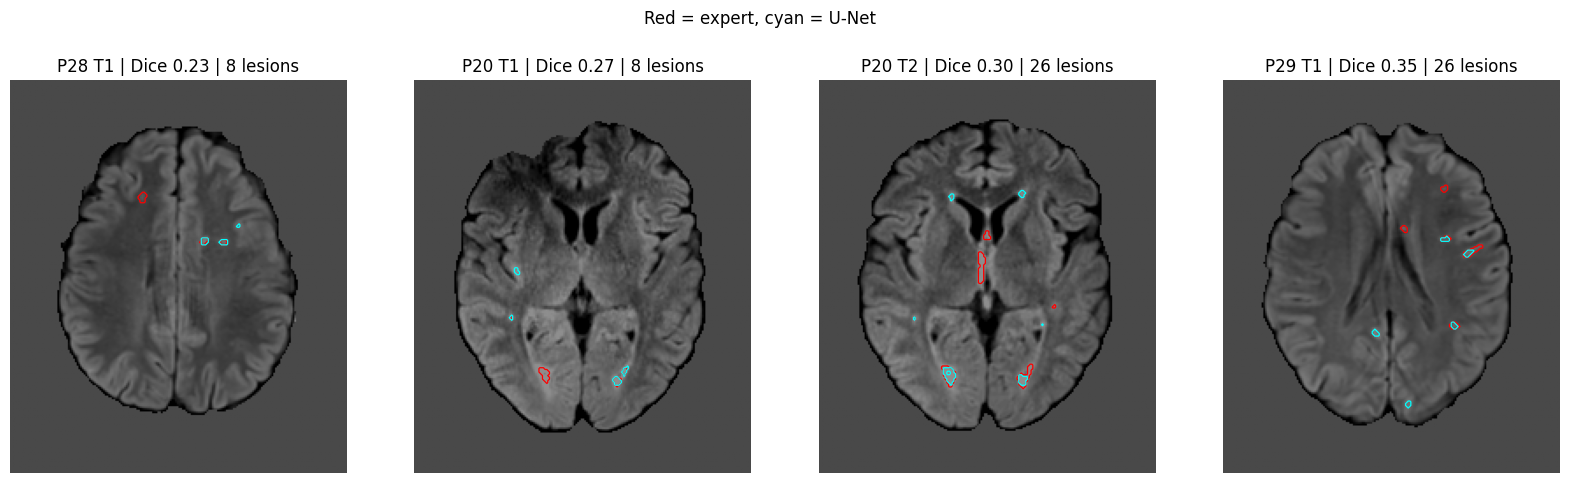

In [ ]:
unet = pd.read_csv(f"{PROC}/unet_results.csv")
base = pd.read_csv(f"{PROC}/baseline_results.csv")      # Dice baseline from the first S2 run
STRUCT = ndi.generate_binary_structure(3, 3)

def pred_path(r):
    return f"{PRED}/{'model_2' if r.role == 'long_B' else 'model_1'}_P{int(r.patient)}_T{int(r.timepoint)}.npz"

# 1. Paired comparison with a patient-level bootstrap
m = unet.merge(base, on=["patient", "timepoint"], suffixes=("_unet", "_base"))
m["diff"] = m.dice_unet - m.dice_base
pp = m.groupby("patient")["diff"].mean()
rng = np.random.default_rng(0)
boots = [rng.choice(pp.values, len(pp)).mean() for _ in range(5000)]
print(f"U-Net beat the baseline in {int((m['diff'] > 0).sum())} of {len(m)} scans")
print("Mean Dice gain per patient:", round(pp.mean(), 3),
      "| 95% CI (patient bootstrap):", np.round(np.percentile(boots, [2.5, 97.5]), 3))

# 2. How big are the false blobs?
rows = []
for _, r in unet.iterrows():
    prob = np.load(pred_path(r))["prob"]
    _, mk, _ = load_scan(int(r.patient), int(r.timepoint))
    lp, n = ndi.label(prob > 127, structure=STRUCT)
    if n == 0:
        continue
    size = np.bincount(lp.ravel(), minlength=n + 1)
    touch = np.bincount(lp[mk], minlength=n + 1) > 0
    rows += [dict(size=int(size[i]), false=not touch[i]) for i in range(1, n + 1)]
b = pd.DataFrame(rows)
b["bin"] = pd.cut(b["size"], [0, 5, 10, 30, 100, 1e9], labels=["1-5", "6-10", "11-30", "31-100", ">100"])
print("\nPredicted blobs by size:")
print(b.groupby("bin", observed=True).agg(blobs=("false", "size"), false_pct=("false", lambda x: round(100 * x.mean(), 1))))

# 3. The four worst scans
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
for ax, (_, r) in zip(axes, unet.sort_values("dice").head(4).iterrows()):
    f, mk, _ = load_scan(int(r.patient), int(r.timepoint))
    pred = np.load(pred_path(r))["prob"] > 127
    k = int(mk.sum(axis=(0, 1)).argmax())
    ax.imshow(f[:, :, k].T.astype(np.float32), cmap="gray", origin="lower", vmin=-2, vmax=5)
    ax.contour(mk[:, :, k].T.astype(float), levels=[0.5], colors="red", linewidths=0.9)
    if pred[:, :, k].any():
        ax.contour(pred[:, :, k].T.astype(float), levels=[0.5], colors="cyan", linewidths=0.9)
    ax.set_title(f"P{int(r.patient)} T{int(r.timepoint)} | Dice {r.dice:.2f} | {int(r.n_true)} lesions"); ax.axis("off")
plt.suptitle("Red = expert, cyan = U-Net"); plt.show()

In [ ]:
from scipy import ndimage as ndi
STRUCT = ndi.generate_binary_structure(3, 3)
unet = pd.read_csv(f"{PROC}/unet_results.csv")

def pred_path(r):
    return f"{PRED}/{'model_2' if r.role == 'long_B' else 'model_1'}_P{int(r.patient)}_T{int(r.timepoint)}.npz"

rows = []
for _, r in unet.iterrows():
    p, t = int(r.patient), int(r.timepoint)
    f, m, b = load_scan(p, t)
    f = f.astype(np.float32)
    prob = np.load(pred_path(r))["prob"].astype(np.float32) / 255
    lab, n = ndi.label(m, structure=STRUCT)
    if n == 0:
        continue
    idx = np.arange(1, n + 1)
    cen = np.array(ndi.center_of_mass(b))
    size = np.bincount(lab.ravel(), minlength=n + 1)[1:]
    mean_z = np.array(ndi.mean(f, lab, idx))
    max_p = np.array(ndi.maximum(prob, lab, idx))
    com = np.array(ndi.center_of_mass(m, lab, idx))
    dist = np.linalg.norm(com - cen, axis=1)
    for i in range(n):
        rows.append(dict(patient=p, timepoint=t, size=int(size[i]), mean_z=float(mean_z[i]),
                         max_prob=float(max_p[i]), dist_center=float(dist[i]),
                         found=bool(max_p[i] * 255 > 127)))
L = pd.DataFrame(rows)
L["size_bin"] = pd.cut(L["size"], [0, 5, 10, 30, 100, 1e9], labels=["1-5", "6-10", "11-30", "31-100", ">100"])

print("Lesions:", len(L), "| found:", round(100 * L.found.mean(), 1), "%\n")
print(L.groupby("size_bin", observed=True).agg(lesions=("found", "size"),
      found_pct=("found", lambda x: round(100 * x.mean(), 1))), "\n")
print(L.groupby("found")[["size", "mean_z", "dist_center"]].median().round(1), "\n")

M = L[~L.found]
print("Missed lesions by the model's highest probability inside them:")
print(pd.cut(M.max_prob, [-0.001, 0.05, 0.2, 0.5]).value_counts().sort_index())

L["central"] = pd.qcut(L.dist_center, 3, labels=["central", "middle", "outer"])
print("\nFound % by distance from the brain's center:")
print(L.groupby("central", observed=True).found.mean().mul(100).round(1))

Lesions: 1932 | found: 78.0 %

          lesions  found_pct
size_bin                    
1-5            90       21.1
6-10           66       39.4
11-30         278       57.6
31-100        822       81.8
>100          676       93.2 

       size  mean_z  dist_center
found                           
False  28.0     1.0         47.4
True   82.0     1.4         47.3 

Missed lesions by the model's highest probability inside them:
max_prob
(-0.001, 0.05]    355
(0.05, 0.2]        39
(0.2, 0.5]         31
Name: count, dtype: int64

Found % by distance from the brain's center:
central
central    77.3
middle     82.9
outer      73.8
Name: found, dtype: float64


In [ ]:
import os, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from google.colab import drive
drive.mount('/content/drive')

PROJECT = "/content/drive/MyDrive/Ms_project"
PROC, SCAN_DIR, PRED = f"{PROJECT}/data_processed", f"{PROJECT}/data_processed/scans", f"{PROJECT}/data_processed/pred_masks"
SB = f"{PROC}/stageB"; os.makedirs(SB, exist_ok=True)

scan_tbl = pd.read_csv(f"{PROC}/scan_table.csv")
pairs = pd.read_csv(f"{PROC}/pairs_table.csv")
STRUCT = ndi.generate_binary_structure(3, 3)

def load_full(p, t):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    return z["flair"], z["mask"] > 0, z["brain"] > 0, z["raw"]

def pred_file(p, t, role):
    return f"{PRED}/{'model_2' if role == 'long_B' else 'model_1'}_P{p}_T{t}.npz"

print("Pairs:", len(pairs), "| patients:", pairs.patient.nunique(), "| flagged:", int(pairs.flag_borderline.sum()))
missing = [(r.patient, r.t_from) for r in pairs.itertuples() if not os.path.exists(pred_file(r.patient, r.t_from, r.role))]
print("Missing U-Net predictions for pair start scans:", missing if missing else "none")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pairs: 39 | patients: 24 | flagged: 3
Missing U-Net predictions for pair start scans: none


prior built from 90 scans in 123s | core voxels: 1706 | components: 3

Ventricle volume in mL (1 voxel = 1 mm3):
count    39.0
mean      9.6
std      14.6
min       0.0
25%       1.7
50%       5.7
75%      10.2
max      58.4
dtype: float64
Scans with an empty mask: 3


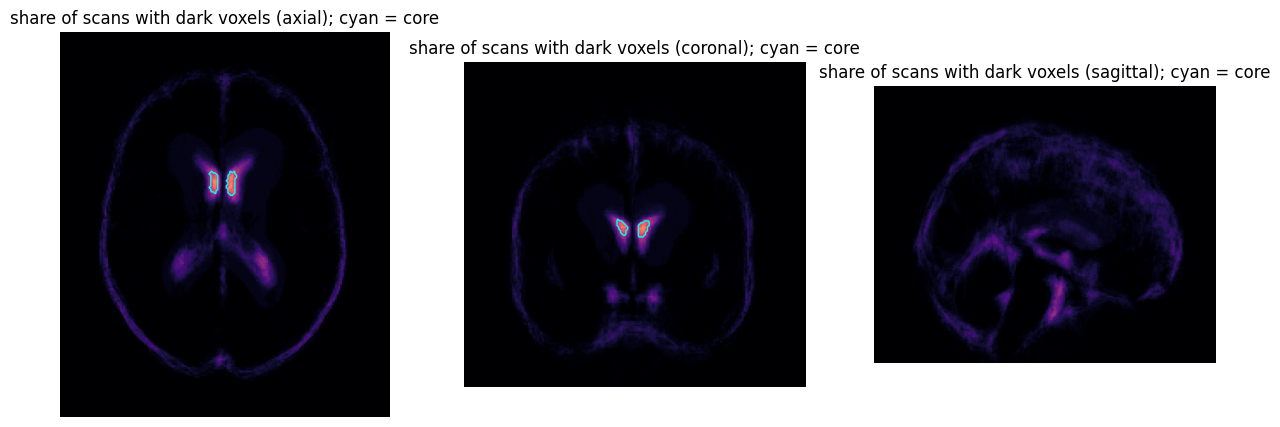

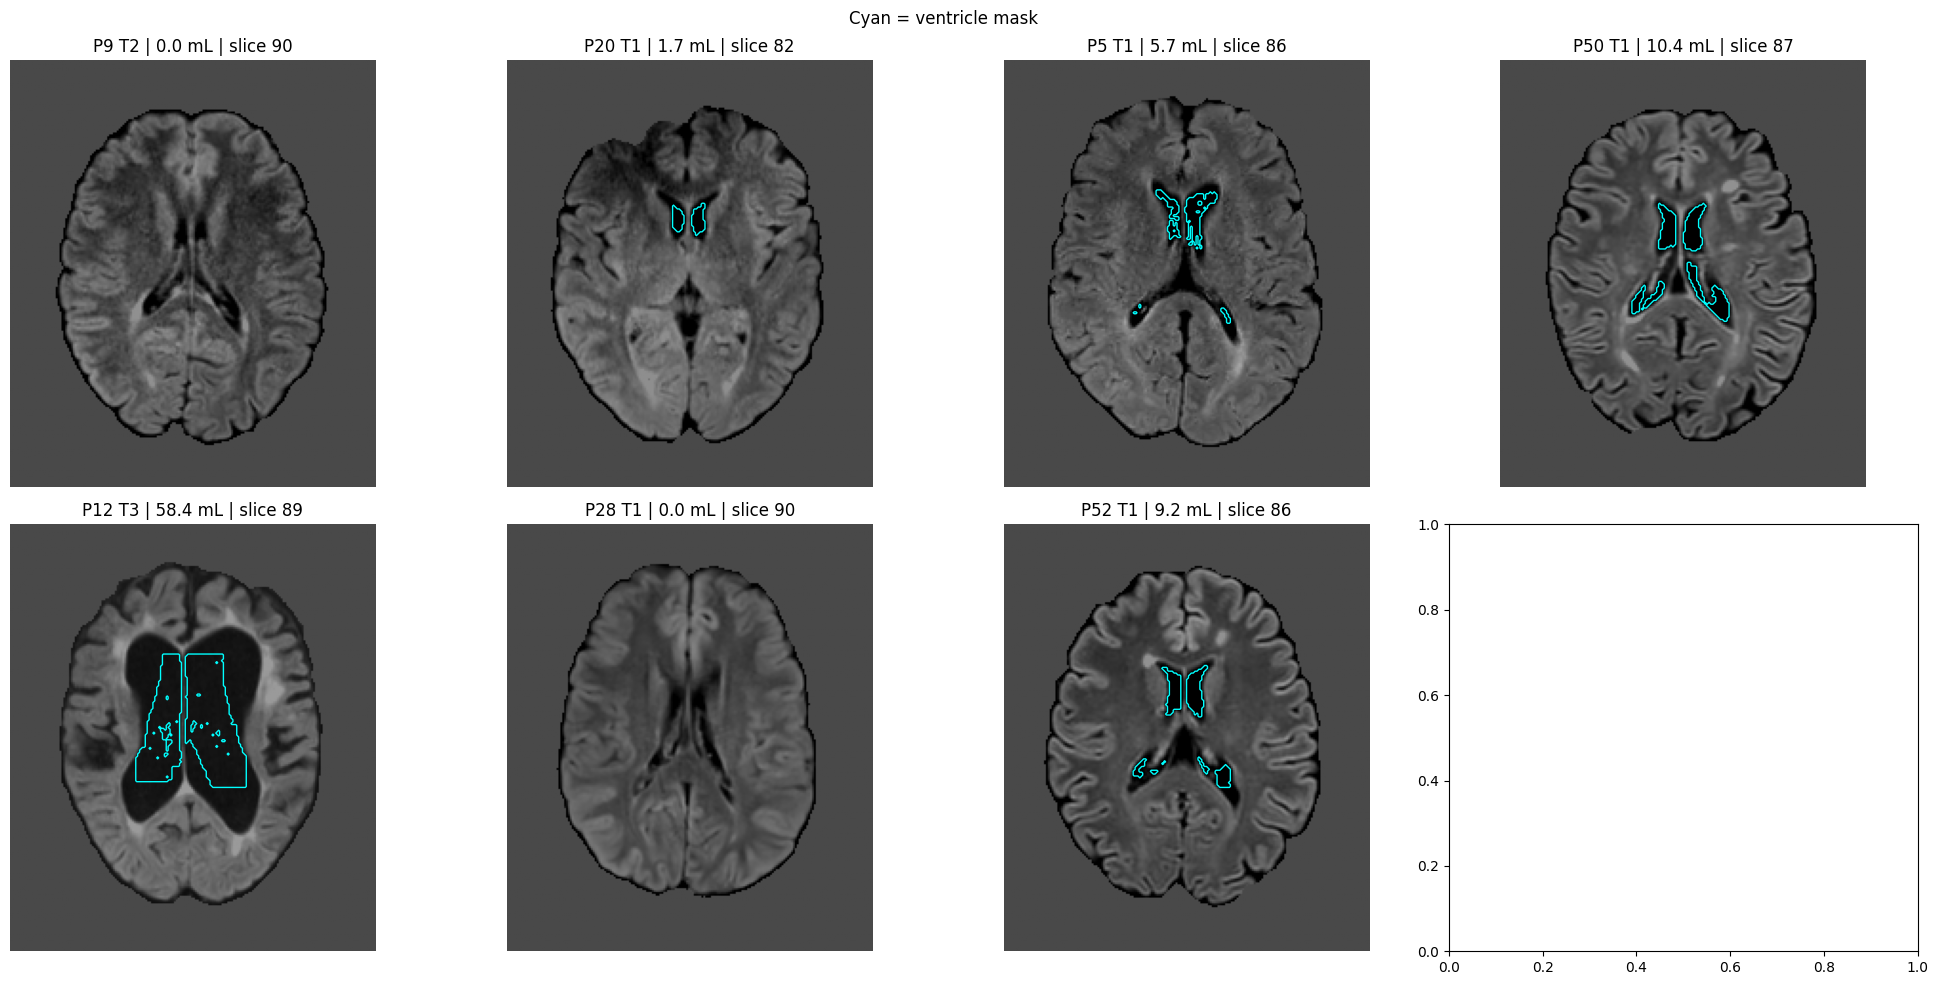

In [ ]:
# ---- knobs (rough first guesses; change them if the pictures say so) ----
DARK_FRAC = 0.25     # dark = below 25% of the scan's median brain intensity
PRIOR_THR = 0.5      # core = dark in at least this share of scans
DILATE = 8           # how far (voxels) a scan's ventricle may extend beyond the core
MIN_COMP = 200       # drop dark specks smaller than this
REDO = True          # True = recompute everything; set False later to resume after a disconnect

def dark_mask(p, t):
    f, m, b, raw = load_full(p, t)
    r = f.astype(np.float32) * raw[3] + raw[2]            # undo the z-score to approximate raw intensity
    return (r < DARK_FRAC * raw[0]) & b

# ---- population prior (excludes the two scale outliers) ----
use = [(p, t) for p, t in scan_tbl[["patient", "timepoint"]].values.tolist() if (p, t) not in {(44, 1), (45, 1)}]
acc = np.zeros((192, 224, 182), np.float32)
t0 = time.time()
for p, t in use:
    acc += dark_mask(p, t)
prior = acc / len(use)
core = prior > PRIOR_THR
lab, n = ndi.label(core, structure=STRUCT)
print(f"prior built from {len(use)} scans in {time.time() - t0:.0f}s | core voxels: {int(core.sum())} | components: {n}")
allowed = ndi.binary_dilation(core, structure=STRUCT, iterations=DILATE)

def ventricle_mask(p, t):
    d = dark_mask(p, t) & allowed
    lab, n = ndi.label(d, structure=STRUCT)
    if n == 0:
        return d
    keep = np.bincount(lab.ravel()) >= MIN_COMP
    keep[0] = False
    return keep[lab]

# ---- compute (and cache) the mask for every pair start scan ----
vol = {}
for r in pairs[["patient", "t_from"]].drop_duplicates().itertuples():
    f = f"{SB}/vent_P{r.patient}_T{r.t_from}.npz"
    if REDO or not os.path.exists(f):
        v = ventricle_mask(r.patient, r.t_from)
        np.savez_compressed(f, vent=v.astype(np.uint8))
    else:
        v = np.load(f)["vent"] > 0
    vol[(r.patient, r.t_from)] = int(v.sum())

V = pd.Series(vol)
print("\nVentricle volume in mL (1 voxel = 1 mm3):")
print((V / 1000).describe().round(1))
print("Scans with an empty mask:", int((V == 0).sum()))

# ---- picture 1: the prior ----
cz = int(ndi.center_of_mass(core)[2]); cy = int(ndi.center_of_mass(core)[1]); cx = int(ndi.center_of_mass(core)[0])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (img, c, title) in zip(ax, [(prior[:, :, cz], core[:, :, cz], "axial"),
                                    (prior[:, cy, :], core[:, cy, :], "coronal"),
                                    (prior[cx, :, :], core[cx, :, :], "sagittal")]):
    a.imshow(img.T, cmap="magma", origin="lower", vmin=0, vmax=1)
    a.contour(c.T.astype(float), levels=[0.5], colors="cyan", linewidths=1)
    a.set_title(f"share of scans with dark voxels ({title}); cyan = core"); a.axis("off")
plt.show()

# ---- picture 2: ventricle masks on 8 scans (extremes, quartiles, and the three borderline-pair scans) ----
Vs = V.sort_values()
keys = [Vs.index[0], Vs.index[len(Vs) // 4], Vs.index[len(Vs) // 2], Vs.index[3 * len(Vs) // 4], Vs.index[-1],
        (28, 1), (20, 1), (52, 1)]
keys = list(dict.fromkeys(k for k in keys if k in vol))
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax_, (p, t) in zip(axes.ravel(), keys):
    f, m, b, raw = load_full(p, t)
    v = np.load(f"{SB}/vent_P{p}_T{t}.npz")["vent"] > 0
    kz = int(ndi.center_of_mass(v)[2]) if v.any() else 90
    ax_.imshow(f[:, :, kz].T.astype(np.float32), cmap="gray", origin="lower", vmin=-2, vmax=5)
    if v[:, :, kz].any():
        ax_.contour(v[:, :, kz].T.astype(float), levels=[0.5], colors="cyan", linewidths=1)
    ax_.set_title(f"P{p} T{t} | {vol[(p, t)] / 1000:.1f} mL | slice {kz}"); ax_.axis("off")
plt.suptitle("Cyan = ventricle mask"); plt.tight_layout(); plt.show()

In [ ]:
rows = []
t0 = time.time()
for r in pairs.itertuples():
    _, ma, ba, _ = load_full(r.patient, r.t_from)
    _, mb, bb, _ = load_full(r.patient, r.t_to)
    cand = ba & ~ma                                    # healthy-looking brain voxels at time 1
    new = mb & cand                                    # positives: lesion at time 2
    dist = ndi.distance_transform_edt(~ma) if ma.any() else np.full(ma.shape, 99.0, np.float32)
    lab, n = ndi.label(new, structure=STRUCT)
    if n:
        idx = np.arange(1, n + 1)
        size = np.bincount(lab.ravel(), minlength=n + 1)[1:]
        mind = np.array(ndi.minimum(dist, lab, idx))
        iso = (mind > 2) & (size >= 3)                 # isolated new lesion (rough rule)
    else:
        size, iso = np.array([]), np.array([], bool)
    rows.append(dict(patient=r.patient, t_from=r.t_from, t_to=r.t_to, role=r.role, flag=r.flag_borderline,
                     cand_vox=int(cand.sum()), base_vox=int(ma.sum()), new_vox=int(new.sum()),
                     iso_vox=int(size[iso].sum()), edge_vox=int(new.sum() - size[iso].sum()),
                     n_iso=int(iso.sum()), lost_vox=int((ma & ~mb).sum())))
    if len(rows) % 10 == 0:
        print(len(rows), "pairs |", f"{time.time() - t0:.0f}s")

T = pd.DataFrame(rows)
T["lost_to_new"] = (T.lost_vox / T.new_vox.replace(0, np.nan)).round(2)
T.to_csv(f"{SB}/label_stats.csv", index=False)

tot = T[["cand_vox", "new_vox", "iso_vox", "edge_vox", "n_iso", "lost_vox"]].sum()
print("\nTotals over", len(T), "pairs:"); print(tot.to_string())
print("Base rate (new voxels / candidate voxels):", f"{tot.new_vox / tot.cand_vox:.5f}")
print("Share of new voxels that are edge growth:", f"{100 * tot.edge_vox / tot.new_vox:.1f}%")
print("Pairs with zero isolated new lesions:", int((T.n_iso == 0).sum()), "of", len(T))
print("Pairs with fewer than 200 new voxels:", int((T.new_vox < 200).sum()))
print("\nMedian lost/new ratio:", T.lost_to_new.median())
print(T.sort_values("new_vox")[["patient", "t_from", "t_to", "role", "flag", "base_vox", "new_vox", "iso_vox", "n_iso", "lost_to_new"]].to_string(index=False))

10 pairs | 18s
20 pairs | 36s
30 pairs | 54s

Totals over 39 pairs:
cand_vox    73355404
new_vox       198671
iso_vox        21985
edge_vox      176686
n_iso            241
lost_vox      178053
Base rate (new voxels / candidate voxels): 0.00271
Share of new voxels that are edge growth: 88.9%
Pairs with zero isolated new lesions: 3 of 39
Pairs with fewer than 200 new voxels: 1

Median lost/new ratio: 0.87
 patient  t_from  t_to   role  flag  base_vox  new_vox  iso_vox  n_iso  lost_to_new
      14       3     4 long_B False     24508        1        0      0       490.00
      20       2     3 long_B False      5807      566       54      1         8.54
       3       1     2 long_A False      2979      647        0      0         3.17
       2       2     3 long_A False      3286      710        0      0         1.93
      28       1     2 long_A  True       822      787      530     14         0.74
       3       3     4 long_A False      2043      957      441      5         1.15
    

Scans below 3.0 mL: [((2, 1), 1.3), ((2, 2), 1.0), ((2, 3), 1.4), ((6, 1), 2.3), ((6, 2), 2.5), ((9, 1), 1.7), ((9, 2), 0.0), ((20, 1), 1.7), ((20, 2), 1.8), ((49, 1), 0.9), ((11, 1), 1.5), ((10, 1), 0.0), ((22, 1), 1.1), ((8, 1), 2.4), ((28, 1), 0.0)] 

P2 T1: dark anywhere 39992 | dark in allowed zone 1645 | largest piece 686 (min 200) | core dark 29.8% | core 20th pct / median 0.23
P2 T2: dark anywhere 52473 | dark in allowed zone 1015 | largest piece 690 (min 200) | core dark 43.5% | core 20th pct / median 0.19
P2 T3: dark anywhere 31150 | dark in allowed zone 1428 | largest piece 920 (min 200) | core dark 50.4% | core 20th pct / median 0.17
P6 T1: dark anywhere 24483 | dark in allowed zone 2377 | largest piece 1359 (min 200) | core dark 40.4% | core 20th pct / median 0.21
P6 T2: dark anywhere 26667 | dark in allowed zone 2751 | largest piece 1688 (min 200) | core dark 42.8% | core 20th pct / median 0.20
P9 T1: dark anywhere 34880 | dark in allowed zone 1962 | largest piece 758 (mi

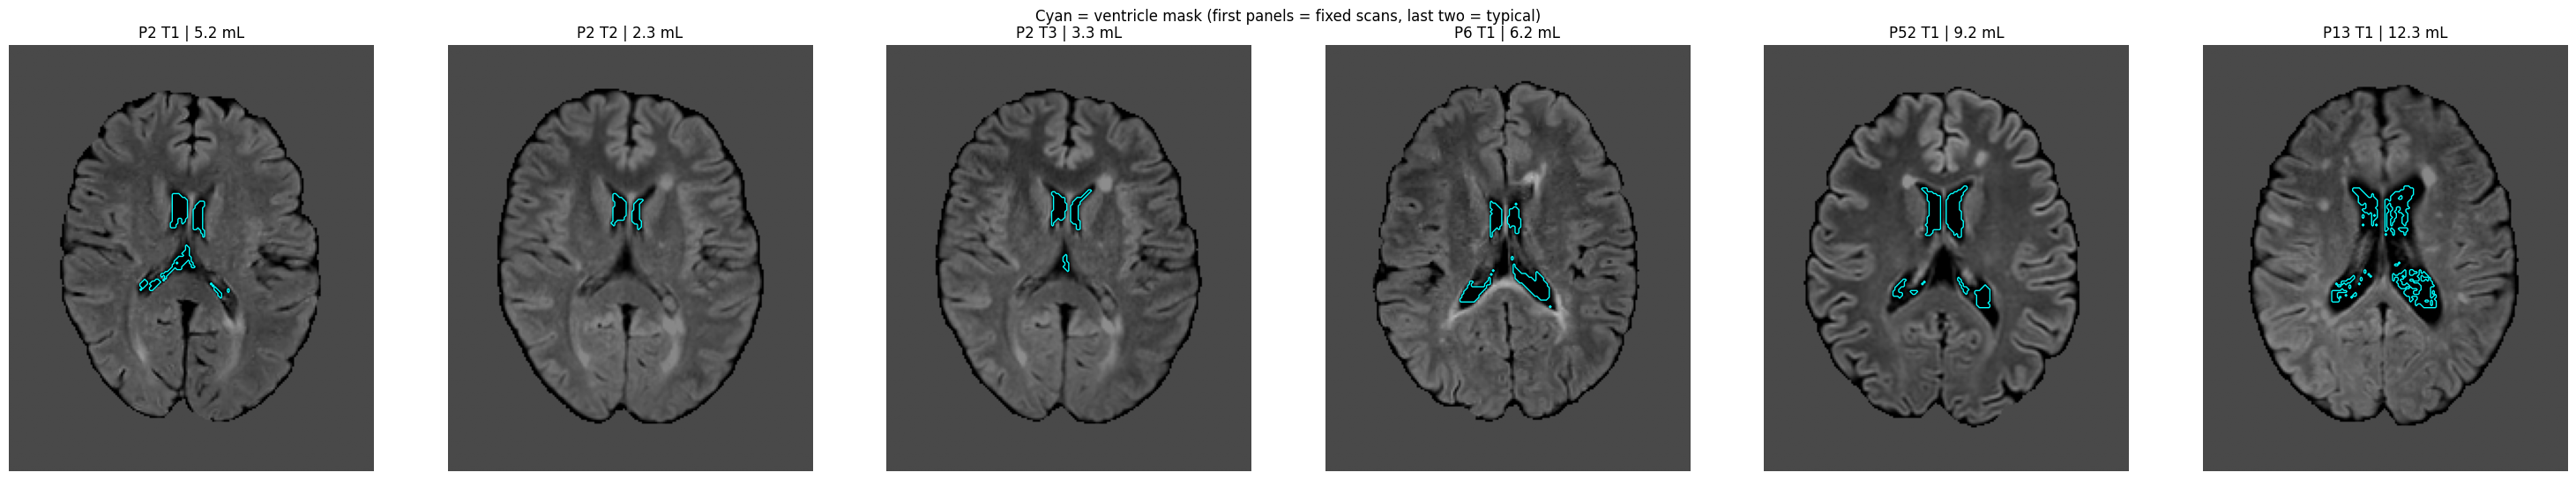

In [ ]:
LOW_ML = 3.0
wide = ndi.binary_dilation(core, structure=STRUCT, iterations=DILATE + 6)

def approx_raw(p, t):
    f, m, b, raw = load_full(p, t)
    return f.astype(np.float32) * raw[3] + raw[2], b, raw

def vent_from(r, b, zone, thr, min_comp):
    d = (r < thr) & b & zone
    lab, n = ndi.label(d, structure=STRUCT)
    if n == 0:
        return d
    sz = np.bincount(lab.ravel()); sz[0] = 0
    return (sz >= min_comp)[lab]

low = [k for k, v in vol.items() if v / 1000 < LOW_ML]
print("Scans below", LOW_ML, "mL:", [(k, round(vol[k] / 1000, 1)) for k in low], "\n")

# --- diagnosis ---
for (p, t) in low:
    r, b, raw = approx_raw(p, t)
    thr = DARK_FRAC * raw[0]
    d = (r < thr) & b
    dz = d & allowed
    lab, n = ndi.label(dz, structure=STRUCT)
    big = int(np.bincount(lab.ravel())[1:].max()) if n else 0
    inside = r[core & b]
    print(f"P{p} T{t}: dark anywhere {int(d.sum())} | dark in allowed zone {int(dz.sum())} | "
          f"largest piece {big} (min {MIN_COMP}) | core dark {100 * float((inside < thr).mean()):.1f}% | "
          f"core 20th pct / median {np.percentile(inside, 20) / raw[0]:.2f}")

# --- fallbacks, only for the low scans ---
fixlog = []
for (p, t) in low:
    r, b, raw = approx_raw(p, t)
    csf = float(np.percentile(r[core & b], 20))
    tiers = [("adaptive threshold", allowed, csf + 0.25 * (raw[0] - csf)),
             ("adaptive + wider zone", wide, csf + 0.25 * (raw[0] - csf)),
             ("40% of median + wider zone", wide, 0.40 * raw[0])]
    for name, zone, thr in tiers:
        v = vent_from(r, b, zone, thr, MIN_COMP)
        if v.sum() / 1000 >= LOW_ML:
            break
    else:
        name = "FAILED (all tiers under %.0f mL)" % LOW_ML
    np.savez_compressed(f"{SB}/vent_P{p}_T{t}.npz", vent=v.astype(np.uint8))
    fixlog.append(dict(patient=p, t=t, old_mL=round(vol[(p, t)] / 1000, 1), new_mL=round(v.sum() / 1000, 1), method=name))
    vol[(p, t)] = int(v.sum())

fx = pd.DataFrame(fixlog); fx.to_csv(f"{SB}/ventricle_fixes.csv", index=False)
print("\n", fx.to_string(index=False))

# --- check: fixed scans plus two typical ones ---
mid = [k for k in sorted(vol, key=vol.get) if k not in low]
show = [(r.patient, r.t) for r in fx.itertuples()][:4] + [mid[len(mid) // 2], mid[3 * len(mid) // 4]]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 5.5))
axes = np.atleast_1d(axes)
for ax_, (p, t) in zip(axes, show):
    f, m, b, raw = load_full(p, t)
    v = np.load(f"{SB}/vent_P{p}_T{t}.npz")["vent"] > 0
    kz = int(ndi.center_of_mass(v)[2]) if v.any() else 90
    ax_.imshow(f[:, :, kz].T.astype(np.float32), cmap="gray", origin="lower", vmin=-2, vmax=5)
    if v[:, :, kz].any():
        ax_.contour(v[:, :, kz].T.astype(float), levels=[0.5], colors="cyan", linewidths=1)
    ax_.set_title(f"P{p} T{t} | {vol[(p, t)] / 1000:.1f} mL"); ax_.axis("off")
plt.suptitle("Cyan = ventricle mask (first panels = fixed scans, last two = typical)"); plt.tight_layout(); plt.show()

In [ ]:
T = pd.read_csv(f"{SB}/label_stats.csv")
print("New voxels:", int(T.new_vox.sum()), "| isolated:", int(T.iso_vox.sum()), "| non-isolated:", int(T.edge_vox.sum()))
print("Isolated new lesions (clusters):", int(T.n_iso.sum()))
print("Pairs with zero isolated lesions:", int((T.n_iso == 0).sum()), "of", len(T))
print("Patients with at least one isolated lesion:", T[T.n_iso > 0].patient.nunique(), "of", T.patient.nunique())
print("Pairs with under 200 new voxels:", int((T.new_vox < 200).sum()))
print("Median lost/new ratio:", T.lost_to_new.median())
print(T[["patient", "t_from", "t_to", "role", "new_vox", "iso_vox", "n_iso"]].sort_values("n_iso", ascending=False).head(10).to_string(index=False))

New voxels: 198671 | isolated: 21985 | non-isolated: 176686
Isolated new lesions (clusters): 241
Pairs with zero isolated lesions: 3 of 39
Patients with at least one isolated lesion: 24 of 24
Pairs with under 200 new voxels: 1
Median lost/new ratio: 0.87
 patient  t_from  t_to   role  new_vox  iso_vox  n_iso
      19       2     3 long_B     6855     1095     22
      13       1     2 long_B     4415     1191     18
      20       1     2 long_B     5002     4242     16
      28       1     2 long_A      787      530     14
       6       1     2 long_A    11936      783     13
      14       2     3 long_B     3355      453     11
      12       1     2 long_A     8845      355     10
      10       1     2 long_A     1875      637     10
       7       1     2 long_B    13963      371      9
       9       1     2 long_A     2063      884      9


In [ ]:
import time
Q, CAP, MIN_VENT = 0.01, 60.0, 3000

# ---- guard: ventricle masks ----
vv = {(int(r.patient), int(r.t_from)):
      int(np.load(f"{SB}/vent_P{int(r.patient)}_T{int(r.t_from)}.npz")["vent"].sum())
      for r in pairs[["patient", "t_from"]].drop_duplicates().itertuples()}
print("Ventricle volume (mL): min", round(min(vv.values()) / 1000, 1),
      "| median", round(float(np.median(list(vv.values()))) / 1000, 1))
print("Empty masks:", [k for k, n in vv.items() if n == 0])
print("Below 3 mL:", [(k, round(n / 1000, 1)) for k, n in vv.items() if 0 < n < MIN_VENT])
assert all(n > 0 for n in vv.values()), "Fix the empty ventricle masks first."

def dist_to(mask):
    if not mask.any():
        return np.full(mask.shape, CAP, np.float32)
    return np.minimum(ndi.distance_transform_edt(~mask), CAP).astype(np.float32)

def lesion_feats(mask, d_full, idx):
    m = mask.astype(np.float32)
    return (d_full.ravel()[idx],
            ndi.uniform_filter(m, size=11, mode="constant").ravel()[idx],
            ndi.uniform_filter(m, size=21, mode="constant").ravel()[idx],
            float(mask.sum()))

def build_pair(r):
    out = f"{SB}/rows_P{int(r.patient)}_T{int(r.t_from)}.pkl"
    if os.path.exists(out):
        return pd.read_pickle(out)
    p, ta, tb = int(r.patient), int(r.t_from), int(r.t_to)
    f, ma, ba, _ = load_full(p, ta)
    _, mb, _, _ = load_full(p, tb)
    f = f.astype(np.float32)
    pa = (np.load(pred_file(p, ta, r.role))["prob"] > 127) & ba
    vent = np.load(f"{SB}/vent_P{p}_T{ta}.npz")["vent"] > 0

    cand = ba & ~ma                                   # healthy-looking brain voxels at time 1
    new = mb & cand                                   # positives
    rng = np.random.default_rng(1000 * p + ta)
    sel = new | (cand & (rng.random(ba.shape) < Q))   # all positives + 1% of the rest
    idx = np.flatnonzero(sel.ravel())

    d_exp_full = dist_to(ma)
    lab, n = ndi.label(new, structure=STRUCT)
    typ_vol = np.zeros(ba.shape, np.int8)
    if n:
        ids = np.arange(1, n + 1)
        size = np.bincount(lab.ravel(), minlength=n + 1)[1:]
        mind = np.array(ndi.minimum(d_exp_full, lab, ids))
        iso = np.zeros(n + 1, bool); iso[1:] = (mind > 2) & (size >= 3)
        typ_vol = np.where(new, 1 + iso[lab].astype(np.int8), 0).astype(np.int8)

    bf = ba.astype(np.float32)
    fl_s5 = (ndi.uniform_filter(f * bf, size=5, mode="constant") /
             (ndi.uniform_filter(bf, size=5, mode="constant") + 1e-6)).ravel()[idx]
    d_vent = dist_to(vent).ravel()[idx]
    d_edge = np.minimum(ndi.distance_transform_edt(ba), CAP).astype(np.float32).ravel()[idx]
    de, d5e, d10e, le = lesion_feats(ma, d_exp_full, idx)
    dp, d5p, d10p, lp = lesion_feats(pa, dist_to(pa), idx)

    x, yy, z = np.unravel_index(idx, ba.shape)
    yv = new.ravel()[idx].astype(np.int8)
    df_ = pd.DataFrame(dict(
        patient=p, ta=ta, tb=tb, role=r.role, flag=bool(r.flag_borderline),
        y=yv, typ=typ_vol.ravel()[idx], w=np.where(yv == 1, 1.0, 1.0 / Q).astype(np.float32),
        cx=x.astype(np.int16), cy=yy.astype(np.int16), cz=z.astype(np.int16),
        d_exp=de, d_vent=d_vent, d_edge=d_edge, flair=f.ravel()[idx], flair_s5=fl_s5,
        d_les_exp=de, dens5_exp=d5e, dens10_exp=d10e, load_exp=le,
        d_les_pred=dp, dens5_pred=d5p, dens10_pred=d10p, load_pred=lp))
    df_.to_pickle(out)
    return df_

t0 = time.time(); parts = []
for i, r in enumerate(pairs.itertuples()):
    parts.append(build_pair(r))
    if (i + 1) % 5 == 0 or i == len(pairs) - 1:
        print(f"{i + 1}/{len(pairs)} pairs | {time.time() - t0:.0f}s")
R = pd.concat(parts, ignore_index=True)
R.to_pickle(f"{SB}/stageB_rows.pkl")

# ---- integrity checks against the label statistics ----
T = pd.read_csv(f"{SB}/label_stats.csv")
print("\nRows:", len(R), "| sampled negatives:", int((R.y == 0).sum()))
print("Positives:", int(R.y.sum()), "| expected", int(T.new_vox.sum()))
print("Non-isolated:", int((R.typ == 1).sum()), "(expected", int(T.edge_vox.sum()), ") | isolated:",
      int((R.typ == 2).sum()), "(expected", int(T.iso_vox.sum()), ")")
print("Weighted base rate:", round(float((R.w * R.y).sum() / R.w.sum()), 5), "(label stats: 0.00271)")
assert int(R.y.sum()) == int(T.new_vox.sum())

Ventricle volume (mL): min 2.3 | median 6.3
Empty masks: []
Below 3 mL: [((2, 2), 2.3)]
5/39 pairs | 30s
10/39 pairs | 56s
15/39 pairs | 82s
20/39 pairs | 110s
25/39 pairs | 136s
30/39 pairs | 163s
35/39 pairs | 189s
39/39 pairs | 209s

Rows: 929580 | sampled negatives: 730909
Positives: 198671 | expected 198671
Non-isolated: 176686 (expected 176686 ) | isolated: 21985 (expected 21985 )
Weighted base rate: 0.00271 (label stats: 0.00271)


In [ ]:
# ===== RESTORE EVERYTHING: run this first after any restart =====
INSTALL_LIBS = True     # installs lightgbm + shap (about a minute); set False if already installed this session
SHOW_SCORES  = False    # True prints the Stage B score tables at the end

import os, glob, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage as ndi
warnings.filterwarnings("ignore")
from google.colab import drive
drive.mount('/content/drive')
if INSTALL_LIBS:
    !pip install lightgbm shap -q
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score as AP

# ---------- paths (handles Ms_project vs MS_project) ----------
ROOT = "/content/drive/MyDrive"
cands = [f"{ROOT}/{d}" for d in ("Ms_project", "MS_project") if os.path.isdir(f"{ROOT}/{d}")]
assert cands, "No Ms_project / MS_project folder found in My Drive."
PROJECT = max(cands, key=lambda p: len(glob.glob(f"{p}/data_processed/**/*", recursive=True)))
RAW, PROC = f"{PROJECT}/data_raw", f"{PROJECT}/data_processed"
SCAN_DIR, PRED, SB, OUT = f"{PROC}/scans", f"{PROC}/pred_masks", f"{PROC}/stageB", f"{PROJECT}/outputs"
for d in (PRED, SB, OUT):
    os.makedirs(d, exist_ok=True)

# ---------- settings used so far ----------
STRUCT = ndi.generate_binary_structure(3, 3)
SMALL = 30
Q, CAP, MIN_VENT = 0.01, 60.0, 3000
BASELINE = dict(thr=1.75, min_size=40)
DETECTION_BASELINE = dict(thr=1.75, min_size=5)
DARK_FRAC, PRIOR_THR, DILATE, MIN_COMP = 0.25, 0.5, 8, 200
SEED = 42
MODELS = {"model_1": dict(train=["train_always", "long_B"], val=["val"], predict=["long_A", "val"]),
          "model_2": dict(train=["train_always", "long_A"], val=["val"], predict=["long_B"])}
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  random_state=0, n_jobs=-1, verbose=-1)

# ---------- tables ----------
def read(path):
    return pd.read_csv(path) if os.path.exists(path) else None
scan_tbl  = read(f"{PROC}/scan_table.csv")
slice_tbl = read(f"{PROC}/slice_table.csv")
split_tbl = read(f"{PROC}/split_table.csv")
pairs     = read(f"{PROC}/pairs_table.csv")
base      = read(f"{PROC}/baseline_results.csv")       # Dice baseline, per scan
unet      = read(f"{PROC}/unet_results.csv")            # U-Net, per scan
T         = read(f"{SB}/label_stats.csv")               # Stage B label statistics

# ---------- helper functions ----------
def load_scan(p, t):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    return z["flair"], z["mask"] > 0, z["brain"] > 0

def load_full(p, t):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    return z["flair"], z["mask"] > 0, z["brain"] > 0, z["raw"]

def pred_file(p, t, role):
    return f"{PRED}/{'model_2' if role == 'long_B' else 'model_1'}_P{p}_T{t}.npz"

def pred_path(r):
    return pred_file(int(r.patient), int(r.timepoint), r.role)

def dice(a, b):
    s = int(a.sum()) + int(b.sum())
    return 2 * int((a & b).sum()) / s if s > 0 else np.nan

def remove_small(pred, min_size):
    if min_size <= 1:
        return pred
    lab, n = ndi.label(pred, structure=STRUCT)
    if n == 0:
        return pred
    keep = np.bincount(lab.ravel()) >= min_size
    keep[0] = False
    return keep[lab]

def eval_pred(pred, m):
    lt, nt = ndi.label(m, structure=STRUCT)
    lp, npr = ndi.label(pred, structure=STRUCT)
    sizes = np.bincount(lt.ravel(), minlength=nt + 1)[1:]
    hit = np.unique(lt[pred & m]); hit = hit[hit > 0]
    det = np.zeros(nt, bool); det[hit - 1] = True
    ov = np.unique(lp[pred & m])
    small = sizes < SMALL
    return dict(dice=dice(pred, m), n_true=nt, n_det=int(det.sum()),
                n_small=int(small.sum()), n_small_det=int(det[small].sum()),
                n_pred=npr, n_fp=int(npr - len(ov)))

def summarize(d):
    g = d.groupby("role")
    return pd.DataFrame({
        "scans": g.size(), "mean_dice": g.dice.mean().round(3),
        "lesions_found_%": (100 * g.n_det.sum() / g.n_true.sum()).round(1),
        "small_found_%": (100 * g.n_small_det.sum() / g.n_small.sum()).round(1),
        "false_blobs_per_scan": g.n_fp.mean().round(1)})

def dist_to(mask):
    if not mask.any():
        return np.full(mask.shape, CAP, np.float32)
    return np.minimum(ndi.distance_transform_edt(~mask), CAP).astype(np.float32)

# ---------- ventricle volumes (read back from the saved masks) ----------
vol = {}
for f in glob.glob(f"{SB}/vent_P*_T*.npz"):
    p, t = os.path.basename(f)[6:-4].split("_T")
    vol[(int(p), int(t))] = int(np.load(f)["vent"].sum())

# ---------- Stage B voxel table and out-of-fold scores ----------
R = pd.read_pickle(f"{SB}/stageB_rows.pkl") if os.path.exists(f"{SB}/stageB_rows.pkl") else None
oof = pd.read_pickle(f"{SB}/oof_predictions.pkl") if os.path.exists(f"{SB}/oof_predictions.pkl") else None

def feats(v):
    return pd.DataFrame({"d_les": R[f"d_les_{v}"].values, "d_vent": R.d_vent.values, "d_edge": R.d_edge.values,
                         "dens5": R[f"dens5_{v}"].values, "dens10": R[f"dens10_{v}"].values,
                         "flair": R.flair.values, "flair_s5": R.flair_s5.values, "load": R[f"load_{v}"].values})

if R is not None:
    y, w, grp = R.y.values, R.w.values, R.patient.values
    folds = list(GroupKFold(n_splits=6).split(R, y, grp))
    views = {"all new voxels":        (np.ones(len(R), bool), (y == 1)),
             "isolated lesions only": (R.typ.values != 1,      (R.typ.values == 2)),
             "far-field (>2 mm)":     (R.d_exp.values > 2,     (y == 1))}

def score_table(keep=None):
    keep = np.ones(len(R), bool) if keep is None else keep
    rows = []
    for (v, m), s in oof.items():
        row = {"features": {"exp": "expert mask", "pred": "U-Net mask"}[v], "model": m}
        for name, (vm, yv) in views.items():
            sel = vm & keep
            row[name] = round(AP(yv[sel], s[sel], sample_weight=w[sel]), 4)
        rows.append(row)
    base_row = {"features": "-", "model": "BASE RATE (random)"}
    for name, (vm, yv) in views.items():
        sel = vm & keep
        base_row[name] = round(float((w[sel] * yv[sel]).sum() / w[sel].sum()), 5)
    return pd.DataFrame(rows + [base_row])

# ---------- status report ----------
cnt = lambda pat: len(glob.glob(pat))
n_scans, n_p1, n_p2 = cnt(f"{SCAN_DIR}/*.npz"), cnt(f"{PRED}/model_1_*.npz"), cnt(f"{PRED}/model_2_*.npz")
n_rows = cnt(f"{SB}/rows_P*_T*.pkl")
checks = [("processed scans", n_scans, 92), ("Model 1 predictions", n_p1, 38), ("Model 2 predictions", n_p2, 31),
          ("ventricle masks", len(vol), 39), ("Stage B per-pair row files", n_rows, 39)]
print("Project folder:", PROJECT, "\n")
for name, found, exp in checks:
    print(f"  {name:28s} {found:>3d}/{exp:<3d} {'ok' if found >= exp else 'INCOMPLETE'}")
for nm, obj in [("scan/pairs/split tables", scan_tbl is not None and pairs is not None and split_tbl is not None),
                ("Dice-baseline results", base is not None), ("U-Net results", unet is not None),
                ("label statistics", T is not None), ("Stage B voxel table", R is not None),
                ("Stage B out-of-fold scores", oof is not None)]:
    print(f"  {nm:28s} {'loaded' if obj else 'MISSING'}")
print("  Model weights:", {m: os.path.exists(f"{OUT}/{m}_best.pt") for m in ("model_1", "model_2")})

if n_scans < 92 or pairs is None:             nxt = "Hour 1 (H1-0, H1-1, H1-3)"
elif base is None:                            nxt = "Stage A baseline (S0, S1, S2)"
elif n_p1 < 38 or n_p2 < 31:                  nxt = "Stage A: switch to GPU, run U0, U1, then U3 and U4"
elif unet is None:                            nxt = "Stage A scoring (U0, then U5)"
elif len(vol) < 39:                           nxt = "Stage B ventricle masks (B1)"
elif T is None:                               nxt = "Stage B label statistics (B2)"
elif R is None or n_rows < 39:                nxt = "Stage B voxel table (B3)"
elif oof is None:                             nxt = "Stage B models (B4)"
else:                                         nxt = "Stage B analysis: B5-1 SHAP, B5-2 ablation, B5-3 calibration, B5-4 risk map"
print("\nNEXT STEP ->", nxt)

if SHOW_SCORES and R is not None and oof is not None:
    print("\nStage B scores, all pairs:\n", score_table().to_string(index=False))
    print("\nWithout the 3 borderline pairs:\n", score_table(~R.flag.values).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/Ms_project 

  processed scans               92/92  ok
  Model 1 predictions           38/38  ok
  Model 2 predictions           31/31  ok
  ventricle masks               39/39  ok
  Stage B per-pair row files     0/39  INCOMPLETE
  scan/pairs/split tables      loaded
  Dice-baseline results        loaded
  U-Net results                loaded
  label statistics             loaded
  Stage B voxel table          MISSING
  Stage B out-of-fold scores   MISSING
  Model weights: {'model_1': True, 'model_2': True}

NEXT STEP -> Stage B voxel table (B3)


In [ ]:
# ===== B4 ALL-IN-ONE: restore + train/score + printable results =====
import os, glob, time, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
from google.colab import drive
drive.mount('/content/drive')
!pip install lightgbm -q
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score as AP

# ---------- project folder (handles Ms_project vs MS_project) ----------
ROOT = "/content/drive/MyDrive"
cands = [f"{ROOT}/{d}" for d in ("Ms_project", "MS_project") if os.path.isdir(f"{ROOT}/{d}")]
assert cands, "No Ms_project / MS_project folder found in My Drive."
PROJECT = max(cands, key=lambda p: len(glob.glob(f"{p}/data_processed/**/*", recursive=True)))
PROC = f"{PROJECT}/data_processed"; SB = f"{PROC}/stageB"; OUT = f"{PROJECT}/outputs"
os.makedirs(OUT, exist_ok=True)

lines = []
def say(*a):
    s = " ".join(str(x) for x in a); print(s); lines.append(s)

# ---------- load the Stage B voxel table ----------
comb = f"{SB}/stageB_rows.pkl"
row_files = sorted(glob.glob(f"{SB}/rows_P*_T*.pkl"))
if os.path.exists(comb):
    R = pd.read_pickle(comb)
elif len(row_files) >= 39:
    R = pd.concat([pd.read_pickle(f) for f in row_files], ignore_index=True)
    R.to_pickle(comb)
else:
    raise RuntimeError(f"Voxel table incomplete: {len(row_files)}/39 per-pair files. Rerun cell B3 first.")

y, w, grp = R.y.values, R.w.values, R.patient.values
Q = 0.01

# ---------- integrity checks against the label statistics ----------
T = pd.read_csv(f"{SB}/label_stats.csv") if os.path.exists(f"{SB}/label_stats.csv") else None
say("=== INTEGRITY ===")
say("Rows:", len(R), "| patients:", R.patient.nunique(), "| pairs:", R.groupby(["patient", "ta"]).ngroups)
say("Sampled negatives:", int((R.y == 0).sum()), "| positives:", int(R.y.sum()),
    "| non-isolated:", int((R.typ == 1).sum()), "| isolated:", int((R.typ == 2).sum()))
if T is not None:
    say("Expected positives:", int(T.new_vox.sum()), "| non-isolated:", int(T.edge_vox.sum()),
        "| isolated:", int(T.iso_vox.sum()))
    assert int(R.y.sum()) == int(T.new_vox.sum()), "Positive count does not match label statistics. Send me these lines."
say("Weighted base rate:", round(float((R.w * R.y).sum() / R.w.sum()), 5), "(expect about 0.0027)")
say("Flagged borderline-pair rows:", int(R.flag.sum()))

# ---------- features, folds, views ----------
def feats(v):
    return pd.DataFrame({"d_les": R[f"d_les_{v}"].values, "d_vent": R.d_vent.values, "d_edge": R.d_edge.values,
                         "dens5": R[f"dens5_{v}"].values, "dens10": R[f"dens10_{v}"].values,
                         "flair": R.flair.values, "flair_s5": R.flair_s5.values, "load": R[f"load_{v}"].values})

def log_feats(X):
    X = X.copy()
    for c in ["d_les", "d_vent", "d_edge", "load"]:
        X[c] = np.log1p(X[c])
    return X

LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  random_state=0, n_jobs=-1, verbose=-1)
folds = list(GroupKFold(n_splits=6).split(R, y, grp))
views = {"all new voxels":        (np.ones(len(R), bool), (y == 1)),
         "isolated lesions only": (R.typ.values != 1,      (R.typ.values == 2)),
         "far-field (>2 mm)":     (R.d_exp.values > 2,     (y == 1))}
say("\nPositives per view:", {k: int(yv[vm].sum()) for k, (vm, yv) in views.items()})

# ---------- train (skips anything already saved) ----------
oof_path = f"{SB}/oof_predictions.pkl"
oof = pd.read_pickle(oof_path) if os.path.exists(oof_path) else {}
if oof and len(next(iter(oof.values()))) != len(R):
    oof = {}                                            # saved scores don't match this table, so redo
MODELS = ["distance only", "logistic regression", "LightGBM"]
t0 = time.time()
for v in ["exp", "pred"]:
    if all((v, m) in oof for m in MODELS):
        print(f"{v}: already trained, skipping")
        continue
    X = feats(v); XL = log_feats(X)
    oof[(v, "distance only")] = -X.d_les.values
    lr_p, gb_p = np.zeros(len(R)), np.zeros(len(R))
    for k, (tr, te) in enumerate(folds):
        lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
        lr.fit(XL.iloc[tr], y[tr]); lr_p[te] = lr.predict_proba(XL.iloc[te])[:, 1]
        gb = lgb.LGBMClassifier(**LGB_PARAMS)
        gb.fit(X.iloc[tr], y[tr]); gb_p[te] = gb.predict_proba(X.iloc[te])[:, 1]
        print(f"{v} fold {k + 1} of 6 done | {time.time() - t0:.0f}s")
    oof[(v, "logistic regression")] = lr_p
    oof[(v, "LightGBM")] = gb_p
    pd.to_pickle(oof, oof_path)                         # saved after each feature version

# ---------- scores ----------
def score_table(keep=None):
    keep = np.ones(len(R), bool) if keep is None else keep
    rows = []
    for (v, m), s in oof.items():
        row = {"features": {"exp": "expert mask", "pred": "U-Net mask"}[v], "model": m}
        for name, (vm, yv) in views.items():
            sel = vm & keep
            row[name] = round(AP(yv[sel], s[sel], sample_weight=w[sel]), 4)
        rows.append(row)
    b = {"features": "-", "model": "BASE RATE (random)"}
    for name, (vm, yv) in views.items():
        sel = vm & keep
        b[name] = round(float((w[sel] * yv[sel]).sum() / w[sel].sum()), 5)
    return pd.DataFrame(rows + [b])

say("\n=== RESULTS (weighted AUPRC; compare with the BASE RATE row) ===")
say("\nAll pairs:\n" + score_table().to_string(index=False))
say("\nWithout the 3 borderline pairs:\n" + score_table(~R.flag.values).to_string(index=False))

prow = []
for pat in np.unique(grp):
    for name, (vm, yv) in views.items():
        sel = vm & (grp == pat)
        if yv[sel].sum() == 0:
            continue
        r_ = {"patient": int(pat), "view": name}
        for m in ["distance only", "LightGBM"]:
            r_[m] = AP(yv[sel], oof[("exp", m)][sel], sample_weight=w[sel])
        prow.append(r_)
PP = pd.DataFrame(prow); PP.to_csv(f"{SB}/per_patient_ap.csv", index=False)
say("\nPer patient (expert-mask features):")
for name in views:
    d = PP[PP.view == name]
    say(f"{name}: {len(d)} patients | median AP distance-only {d['distance only'].median():.4f}, "
        f"LightGBM {d['LightGBM'].median():.4f} | LightGBM higher in {int((d.LightGBM > d['distance only']).sum())} of {len(d)}")

# ---------- save a text copy ----------
with open(f"{OUT}/b4_results.txt", "w") as f:
    f.write("\n".join(lines))
say("\nSaved a copy to:", f"{OUT}/b4_results.txt")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== INTEGRITY ===
Rows: 929580 | patients: 24 | pairs: 39
Sampled negatives: 730909 | positives: 198671 | non-isolated: 176686 | isolated: 21985
Expected positives: 198671 | non-isolated: 176686 | isolated: 21985
Weighted base rate: 0.00271 (expect about 0.0027)
Flagged borderline-pair rows: 63599

Positives per view: {'all new voxels': 198671, 'isolated lesions only': 21985, 'far-field (>2 mm)': 80988}
exp fold 1 of 6 done | 17s
exp fold 2 of 6 done | 37s
exp fold 3 of 6 done | 55s
exp fold 4 of 6 done | 72s
exp fold 5 of 6 done | 90s
exp fold 6 of 6 done | 108s
pred fold 1 of 6 done | 126s
pred fold 2 of 6 done | 143s
pred fold 3 of 6 done | 160s
pred fold 4 of 6 done | 179s
pred fold 5 of 6 done | 197s
pred fold 6 of 6 done | 214s

=== RESULTS (weighted AUPRC; compare with the BASE RATE row) ===

All pairs:
   features               model  all new voxels  

=== PART 1: mean per-patient AP difference [95% patient-bootstrap CI] | patients where the first is higher ===

all new voxels (24 patients)
  logistic regression minus distance-only (expert features): +0.0438 [+0.0291, +0.0602] | 21 of 24
  LightGBM minus distance-only (expert features): +0.0672 [+0.0441, +0.0909] | 22 of 24
  logistic regression minus LightGBM (expert features): -0.0234 [-0.0461, -0.0019] | 8 of 24
  U-Net features minus expert features (logistic regression): +0.0475 [+0.0247, +0.0707] | 21 of 24
  U-Net features minus expert features (distance only): +0.0472 [+0.0253, +0.0697] | 18 of 24

isolated lesions only (24 patients)
  logistic regression minus distance-only (expert features): +0.0006 [+0.0003, +0.0009] | 23 of 24
  LightGBM minus distance-only (expert features): +0.0010 [+0.0006, +0.0015] | 24 of 24
  logistic regression minus LightGBM (expert features): -0.0005 [-0.0008, -0.0002] | 5 of 24
  U-Net features minus expert features (logistic regression): +0.024

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== 1. SHAP: mean |SHAP| per feature (expert-mask features, model trained on all patients) ===
(sampled rows are ~21% positives because negatives were subsampled; importance describes that sample)
          all rows  far-field rows (>2 mm)
d_les        1.291                   0.907
load         0.689                   0.721
flair        0.688                   0.641
d_edge       0.543                   0.584
d_vent       0.538                   0.530
dens5        0.345                   0.254
flair_s5     0.286                   0.276
dens10       0.091                   0.071


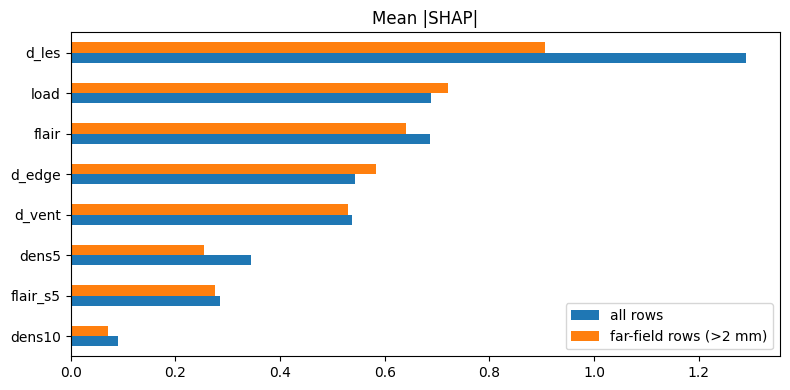

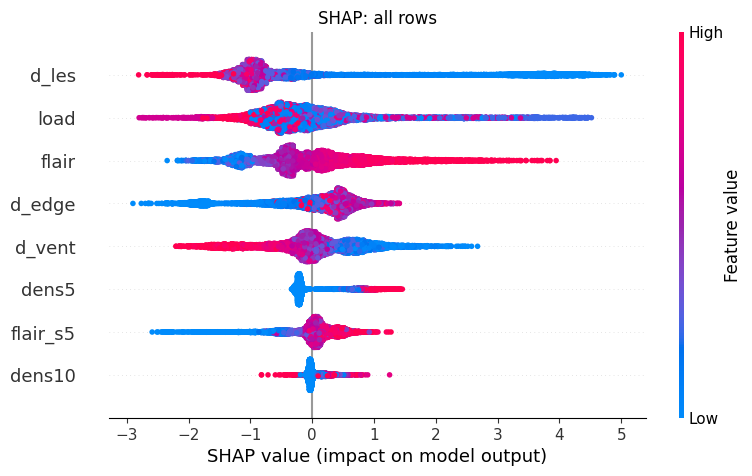

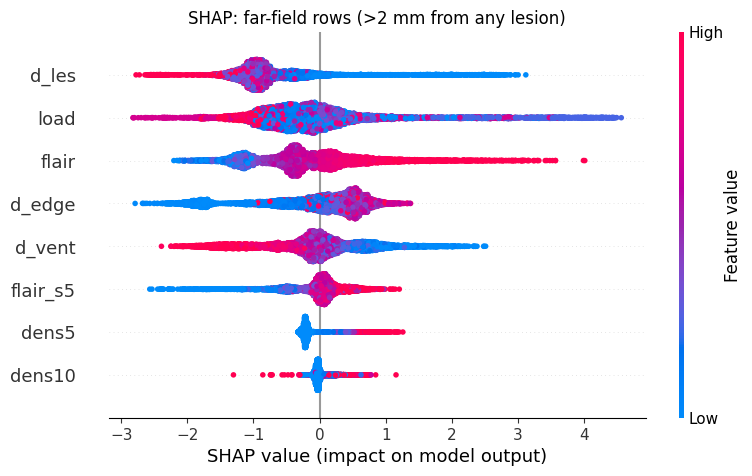


=== 2. CALIBRATION (LightGBM, expert features, out-of-fold) ===
Average predicted risk: 0.00182 | observed rate: 0.00271
all candidates - (predicted, observed) per bin:
 [[0.000e+00 1.000e-05]
 [0.000e+00 2.100e-04]
 [1.000e-05 3.400e-04]
 [2.000e-05 3.700e-04]
 [4.000e-05 4.300e-04]
 [6.000e-05 4.700e-04]
 [9.000e-05 5.900e-04]
 [1.500e-04 1.030e-03]
 [3.600e-04 1.720e-03]
 [1.667e-02 2.094e-02]]
far-field (>2 mm) - (predicted, observed) per bin:
 [[0.00e+00 1.00e-05]
 [0.00e+00 2.10e-04]
 [1.00e-05 3.40e-04]
 [2.00e-05 3.80e-04]
 [3.00e-05 4.20e-04]
 [5.00e-05 4.70e-04]
 [9.00e-05 5.70e-04]
 [1.50e-04 9.80e-04]
 [3.20e-04 1.64e-03]
 [5.66e-03 5.99e-03]]


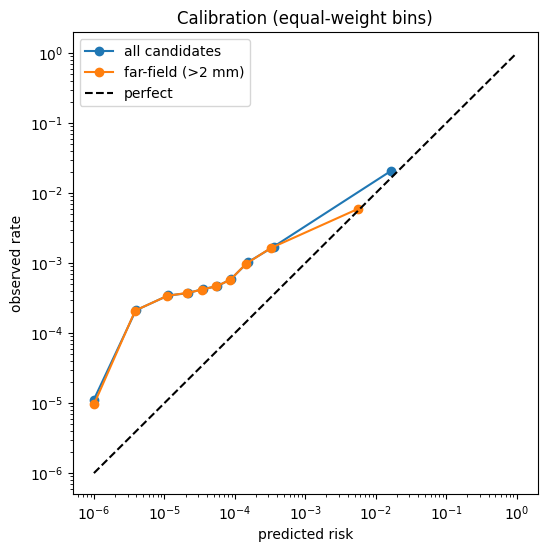

full model (8 features) {'all new voxels': np.float64(0.1596), 'isolated lesions only': np.float64(0.0008), 'far-field (>2 mm)': np.float64(0.0124)} | 48s
drop: lesion proximity + density {'all new voxels': np.float64(0.0903), 'isolated lesions only': np.float64(0.0034), 'far-field (>2 mm)': np.float64(0.0132)} | 95s
drop: ventricle distance {'all new voxels': np.float64(0.1383), 'isolated lesions only': np.float64(0.0007), 'far-field (>2 mm)': np.float64(0.0105)} | 146s
drop: brain-surface distance {'all new voxels': np.float64(0.1613), 'isolated lesions only': np.float64(0.0007), 'far-field (>2 mm)': np.float64(0.0132)} | 197s
drop: FLAIR brightness {'all new voxels': np.float64(0.1168), 'isolated lesions only': np.float64(0.0004), 'far-field (>2 mm)': np.float64(0.0057)} | 242s
only: lesion proximity + density {'all new voxels': np.float64(0.1189), 'isolated lesions only': np.float64(0.0003), 'far-field (>2 mm)': np.float64(0.0054)} | 288s

=== 3. ABLATION (weighted AUPRC; faster Li

AttributeError: '_io.TextIOWrapper' object has no attribute 'astype'

In [ ]:
# ===== B5 ALL-IN-ONE: SHAP, calibration, ablation, risk map =====
RUN_SHAP, RUN_CALIBRATION, RUN_ABLATION, RUN_RISKMAP = True, True, True, True
RM_PAIR = (13, 1, 2)            # (patient, t_from, t_to) for the risk-map figure

import os, glob, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage as ndi
warnings.filterwarnings("ignore")
from google.colab import drive
drive.mount('/content/drive')
!pip install lightgbm shap -q
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score as AP

# ---------- paths ----------
ROOT = "/content/drive/MyDrive"
cands = [f"{ROOT}/{d}" for d in ("Ms_project", "MS_project") if os.path.isdir(f"{ROOT}/{d}")]
assert cands, "No Ms_project / MS_project folder found in My Drive."
PROJECT = max(cands, key=lambda p: len(glob.glob(f"{p}/data_processed/**/*", recursive=True)))
PROC = f"{PROJECT}/data_processed"; SCAN_DIR, SB, OUT = f"{PROC}/scans", f"{PROC}/stageB", f"{PROJECT}/outputs"
os.makedirs(OUT, exist_ok=True)
Q, CAP = 0.01, 60.0
STRUCT = ndi.generate_binary_structure(3, 3)
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  random_state=0, n_jobs=-1, verbose=-1)

# ---------- data ----------
assert os.path.exists(f"{SB}/stageB_rows.pkl") and os.path.exists(f"{SB}/oof_predictions.pkl"), \
    "Stage B table or scores missing. Run the B4 all-in-one cell first."
if "R" not in globals(): R = pd.read_pickle(f"{SB}/stageB_rows.pkl")
if "oof" not in globals(): oof = pd.read_pickle(f"{SB}/oof_predictions.pkl")
y, w, grp = R.y.values, R.w.values, R.patient.values
pairs = pd.read_csv(f"{PROC}/pairs_table.csv")

def feats(v):
    return pd.DataFrame({"d_les": R[f"d_les_{v}"].values, "d_vent": R.d_vent.values, "d_edge": R.d_edge.values,
                         "dens5": R[f"dens5_{v}"].values, "dens10": R[f"dens10_{v}"].values,
                         "flair": R.flair.values, "flair_s5": R.flair_s5.values, "load": R[f"load_{v}"].values})
views = {"all new voxels": (np.ones(len(R), bool), y == 1),
         "isolated lesions only": (R.typ.values != 1, R.typ.values == 2),
         "far-field (>2 mm)": (R.d_exp.values > 2, y == 1)}
folds = list(GroupKFold(n_splits=6).split(R, y, grp))
lines = []
def say(*a):
    s = " ".join(str(x) for x in a); print(s); lines.append(s)

# ================= 1. SHAP =================
if RUN_SHAP:
    import shap
    X = feats("exp")
    final = lgb.LGBMClassifier(**LGB_PARAMS).fit(X, y)
    def shap_vals(Xs):
        sv = shap.TreeExplainer(final).shap_values(Xs)
        if isinstance(sv, list): sv = sv[-1]
        sv = np.asarray(sv)
        return sv[:, :, -1] if sv.ndim == 3 else sv
    rng = np.random.default_rng(0)
    idx_all = rng.choice(len(R), 8000, replace=False)
    idx_far = rng.choice(np.flatnonzero(R.d_exp.values > 2), 8000, replace=False)
    sv_all, sv_far = shap_vals(X.iloc[idx_all]), shap_vals(X.iloc[idx_far])
    imp = pd.DataFrame({"all rows": np.abs(sv_all).mean(0), "far-field rows (>2 mm)": np.abs(sv_far).mean(0)}, index=X.columns)
    say("=== 1. SHAP: mean |SHAP| per feature (expert-mask features, model trained on all patients) ===")
    say("(sampled rows are ~21% positives because negatives were subsampled; importance describes that sample)")
    say(imp.sort_values("all rows", ascending=False).round(3).to_string())
    imp.sort_values("all rows").plot.barh(figsize=(8, 4)); plt.title("Mean |SHAP|"); plt.tight_layout()
    plt.savefig(f"{OUT}/shap_importance.png", dpi=150); plt.show()
    for nm, sv, ix in [("all rows", sv_all, idx_all), ("far-field rows (>2 mm from any lesion)", sv_far, idx_far)]:
        shap.summary_plot(sv, X.iloc[ix], show=False); plt.title(f"SHAP: {nm}")
        plt.savefig(f"{OUT}/shap_beeswarm_{'far' if 'far' in nm else 'all'}.png", dpi=150, bbox_inches="tight"); plt.show()

# ================= 2. CALIBRATION =================
if RUN_CALIBRATION:
    p = oof[("exp", "LightGBM")]
    pt = p * Q / (p * Q + (1 - p))                      # undo the 1% negative sampling
    def calib(sel, nb=10):
        idx = np.flatnonzero(sel); o = idx[np.argsort(pt[idx])]
        cw = np.cumsum(w[o]); cuts = np.searchsorted(cw, np.linspace(0, cw[-1], nb + 1)[1:-1])
        return np.array([(np.average(pt[b], weights=w[b]), np.average(y[b], weights=w[b])) for b in np.split(o, cuts) if len(b)])
    say("\n=== 2. CALIBRATION (LightGBM, expert features, out-of-fold) ===")
    say("Average predicted risk:", round(float(np.average(pt, weights=w)), 5), "| observed rate:", round(float(np.average(y, weights=w)), 5))
    plt.figure(figsize=(6, 6))
    for nm, sel in [("all candidates", np.ones(len(R), bool)), ("far-field (>2 mm)", R.d_exp.values > 2)]:
        c = calib(sel)
        say(nm, "- (predicted, observed) per bin:\n", np.round(c, 5))
        plt.loglog(np.clip(c[:, 0], 1e-6, 1), np.clip(c[:, 1], 1e-6, 1), "o-", label=nm)
    plt.plot([1e-6, 1], [1e-6, 1], "k--", label="perfect"); plt.xlabel("predicted risk"); plt.ylabel("observed rate")
    plt.legend(); plt.title("Calibration (equal-weight bins)"); plt.savefig(f"{OUT}/calibration.png", dpi=150); plt.show()

# ================= 3. ABLATION =================
if RUN_ABLATION:
    GROUPS = {"lesion proximity + density": ["d_les", "dens5", "dens10", "load"], "ventricle distance": ["d_vent"],
              "brain-surface distance": ["d_edge"], "FLAIR brightness": ["flair", "flair_s5"]}
    FAST = dict(LGB_PARAMS, n_estimators=150, learning_rate=0.1)
    X = feats("exp")
    def cv_scores(cols):
        Xc = X[cols]; p_ = np.zeros(len(R))
        for tr, te in folds:
            p_[te] = lgb.LGBMClassifier(**FAST).fit(Xc.iloc[tr], y[tr]).predict_proba(Xc.iloc[te])[:, 1]
        return {nm: round(AP(yv[vm], p_[vm], sample_weight=w[vm]), 4) for nm, (vm, yv) in views.items()}
    configs = {"full model (8 features)": list(X.columns)}
    for g, cols in GROUPS.items(): configs[f"drop: {g}"] = [c for c in X.columns if c not in cols]
    configs["only: lesion proximity + density"] = GROUPS["lesion proximity + density"]
    res, t0 = {}, time.time()
    for nm, cols in configs.items():
        res[nm] = cv_scores(cols); print(nm, res[nm], f"| {time.time() - t0:.0f}s")
    A = pd.DataFrame(res).T; A.to_csv(f"{OUT}/stageB_ablation.csv")
    say("\n=== 3. ABLATION (weighted AUPRC; faster LightGBM setting, so not identical to B4) ===")
    say(A.to_string()); say("\nChange vs full model:\n" + (A - A.loc["full model (8 features)"]).round(4).to_string())

# ================= 4. RISK MAP =================
if RUN_RISKMAP:
    from matplotlib.colors import LogNorm
    P, TA, TB = RM_PAIR
    rr = pairs[(pairs.patient == P) & (pairs.t_from == TA) & (pairs.t_to == TB)]
    assert len(rr), f"Pair {RM_PAIR} not found in the pairs table."
    def load_full(p, t):
        z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz"); return z["flair"], z["mask"] > 0, z["brain"] > 0
    def dist_to(m):
        if not m.any(): return np.full(m.shape, CAP, np.float32)
        return np.minimum(ndi.distance_transform_edt(~m), CAP).astype(np.float32)
        f, ma, ba = load_full(P, TA)
    f = f.astype(np.float32)
    _, mb, _ = load_full(P, TB)
    vent = np.load(f"{SB}/vent_P{P}_T{TA}.npz")["vent"] > 0
    bf = ba.astype(np.float32)
    fv = {"d_les": dist_to(ma),
          "d_vent": dist_to(vent),
          "d_edge": np.minimum(ndi.distance_transform_edt(ba), CAP).astype(np.float32),
          "dens5": ndi.uniform_filter(ma.astype(np.float32), size=11, mode="constant"),
          "dens10": ndi.uniform_filter(ma.astype(np.float32), size=21, mode="constant"),
          "flair": f,
          "flair_s5": ndi.uniform_filter(f * bf, size=5, mode="constant")
                      / (ndi.uniform_filter(bf, size=5, mode="constant") + 1e-6)}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
P13 T1->T2, slice 99: 152 new voxels among 18270 candidates
New-voxel rate in this slice: 0.00832
Top 1% risk voxels: rate 0.28962 = 34.8x the slice rate
Share of this slice's new voxels inside the top 5% risk voxels: 60.5%


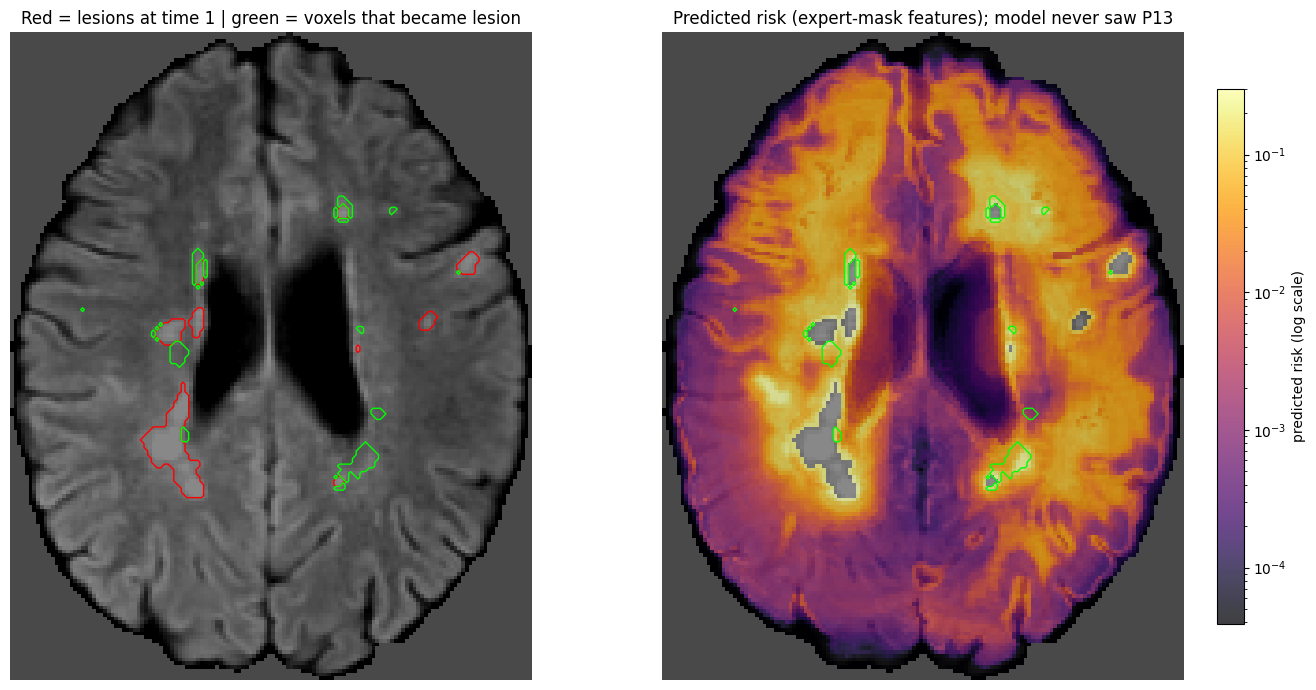

In [ ]:
# ===== RISK MAP (standalone) =====
RM_PAIR = (13, 1, 2)      # (patient, t_from, t_to); try other pairs from pairs_table.csv

import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from matplotlib.colors import LogNorm
warnings.filterwarnings("ignore")
from google.colab import drive
drive.mount('/content/drive')
!pip install lightgbm -q
import lightgbm as lgb

ROOT = "/content/drive/MyDrive"
cands = [f"{ROOT}/{d}" for d in ("Ms_project", "MS_project") if os.path.isdir(f"{ROOT}/{d}")]
assert cands, "No Ms_project / MS_project folder found in My Drive."
PROJECT = max(cands, key=lambda p: len(glob.glob(f"{p}/data_processed/**/*", recursive=True)))
PROC = f"{PROJECT}/data_processed"
SCAN_DIR = f"{PROC}/scans"
SB = f"{PROC}/stageB"
OUT = f"{PROJECT}/outputs"
os.makedirs(OUT, exist_ok=True)
Q, CAP = 0.01, 60.0
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  random_state=0, n_jobs=-1, verbose=-1)

if "R" not in globals():
    R = pd.read_pickle(f"{SB}/stageB_rows.pkl")
y = R.y.values
grp = R.patient.values
pairs = pd.read_csv(f"{PROC}/pairs_table.csv")

def feats(v):
    return pd.DataFrame({
        "d_les": R[f"d_les_{v}"].values,
        "d_vent": R.d_vent.values,
        "d_edge": R.d_edge.values,
        "dens5": R[f"dens5_{v}"].values,
        "dens10": R[f"dens10_{v}"].values,
        "flair": R.flair.values,
        "flair_s5": R.flair_s5.values,
        "load": R[f"load_{v}"].values,
    })

def load_full(p, t):
    z = np.load(f"{SCAN_DIR}/P{p}_T{t}.npz")
    return z["flair"], z["mask"] > 0, z["brain"] > 0

def dist_to(m):
    if not m.any():
        return np.full(m.shape, CAP, np.float32)
    return np.minimum(ndi.distance_transform_edt(~m), CAP).astype(np.float32)

P, TA, TB = RM_PAIR
hit = pairs[(pairs.patient == P) & (pairs.t_from == TA) & (pairs.t_to == TB)]
assert len(hit) == 1, f"Pair {RM_PAIR} not found in pairs_table.csv"

# ---- features for every voxel of this scan ----
fl, ma, ba = load_full(P, TA)
fl = fl.astype(np.float32)
_, mb, _ = load_full(P, TB)
vent = np.load(f"{SB}/vent_P{P}_T{TA}.npz")["vent"] > 0
bf = ba.astype(np.float32)
mf = ma.astype(np.float32)
smooth_num = ndi.uniform_filter(fl * bf, size=5, mode="constant")
smooth_den = ndi.uniform_filter(bf, size=5, mode="constant") + 1e-6
fv = {
    "d_les": dist_to(ma),
    "d_vent": dist_to(vent),
    "d_edge": np.minimum(ndi.distance_transform_edt(ba), CAP).astype(np.float32),
    "dens5": ndi.uniform_filter(mf, size=11, mode="constant"),
    "dens10": ndi.uniform_filter(mf, size=21, mode="constant"),
    "flair": fl,
    "flair_s5": smooth_num / smooth_den,
}

# ---- candidates, true new voxels, and the slice with the most new lesion ----
cand = ba & ~ma
new = mb & cand
k = int(new.sum(axis=(0, 1)).argmax())
sl = cand[:, :, k]

Xs = pd.DataFrame({c: fv[c][:, :, k][sl] for c in fv})
Xs["load"] = float(ma.sum())

# ---- train on every patient EXCEPT this one, then score the slice ----
Xtr = feats("exp")
model = lgb.LGBMClassifier(**LGB_PARAMS)
model.fit(Xtr[grp != P], y[grp != P])
ps = model.predict_proba(Xs[Xtr.columns])[:, 1]
pt_s = ps * Q / (ps * Q + (1 - ps))
risk = np.full(sl.shape, np.nan, np.float32)
risk[sl] = pt_s

# ---- enrichment numbers ----
lab_s = new[:, :, k][sl].astype(int)
top1 = ps >= np.quantile(ps, 0.99)
top5 = ps >= np.quantile(ps, 0.95)
rate_all = lab_s.mean()
rate_top1 = lab_s[top1].mean()
print(f"P{P} T{TA}->T{TB}, slice {k}: {int(lab_s.sum())} new voxels among {len(lab_s)} candidates")
print(f"New-voxel rate in this slice: {rate_all:.5f}")
print(f"Top 1% risk voxels: rate {rate_top1:.5f} = {rate_top1 / max(rate_all, 1e-9):.1f}x the slice rate")
print(f"Share of this slice's new voxels inside the top 5% risk voxels: {100 * lab_s[top5].sum() / max(lab_s.sum(), 1):.1f}%")

# ---- figure ----
xs_, ys_ = np.where(ba[:, :, k])
x0, x1, y0, y1 = xs_.min(), xs_.max() + 1, ys_.min(), ys_.max() + 1
def crop(a):
    return a[x0:x1, y0:y1].T

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a in ax:
    a.imshow(crop(fl[:, :, k]), cmap="gray", origin="lower", vmin=-2, vmax=5)
    a.axis("off")
ax[0].contour(crop(ma[:, :, k]).astype(float), levels=[0.5], colors="red", linewidths=1)
ax[0].contour(crop(new[:, :, k]).astype(float), levels=[0.5], colors="lime", linewidths=1)
ax[0].set_title("Red = lesions at time 1 | green = voxels that became lesion")
lo_, hi_ = np.nanpercentile(pt_s, 5), np.nanpercentile(pt_s, 99.9)
im = ax[1].imshow(np.ma.masked_invalid(crop(risk)), cmap="inferno", alpha=0.75,
                  origin="lower", norm=LogNorm(vmin=lo_, vmax=hi_))
ax[1].contour(crop(new[:, :, k]).astype(float), levels=[0.5], colors="lime", linewidths=1)
plt.colorbar(im, ax=ax[1], fraction=0.04, label="predicted risk (log scale)")
ax[1].set_title(f"Predicted risk (expert-mask features); model never saw P{P}")
plt.tight_layout()
plt.savefig(f"{OUT}/risk_map_P{P}_T{TA}_{TB}.png", dpi=150, bbox_inches="tight")
plt.show()